<a href="https://colab.research.google.com/github/Bernardocoding/Data-Science/blob/main/ConfibilidadeDeSistemas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelagem de RUL — NASA C-MAPSS FD001 (Colab GPU)
### Confiabilidade probabilística (Trilha A) × Machine/Deep Learning (Trilha B)

**Objetivo.** Comparar, sob o mesmo protocolo e sem vazamento de dados, modelos clássicos de confiabilidade e modelos de ML/DL para prever a vida útil remanescente (RUL), avaliando métricas de regressão, a NASA Score assimétrica, inferência estatística pareada por motor e o impacto operacional numa política de manutenção preventiva.

**Desenho experimental**

| Trilha | Modelo | Usa sensores? |
|---|---|---|
| A1 | Weibull 2P, Lognormal 2P, Weibull 3P → $\widehat{\text{RUL}} = \text{MRL}(t_i)$ | não (só idade) |
| A2 | Processo de Wiener sobre Health Index (HI-PCA / HI-Ridge), deriva populacional e Bayesiana individual | sim |
| B1 | XGBoost GPU com features causais de janela móvel | sim |
| B2 | LSTM empilhada (PyTorch, AMP) | sim |
| B3 | 1D-CNN temporal (PyTorch, AMP) | sim |
| B4 | Melhor rede (B2/B3) com perda assimétrica inspirada na NASA Score | sim |
| B5 | Ablação do teto de RUL (115/125/135) com XGBoost | sim |

**Protocolo (contrato da EDA, `eda_summary.json`).** 14 sensores; `seq_len=30`; alvo piecewise com teto 125 **só no treino**; avaliação sempre contra o RUL real sem corte; `StandardScaler` ajustado só no treino de cada fold; `GroupKFold(5)` por `unit_id`; `SEED=42`.

- **OOF (validação):** em cada fold, os motores de validação (que rodam até a falha) são avaliados em **5 pontos de corte por motor** sorteados uniformemente em $[\text{seq\_len}, T_f]$ (snapshots que imitam o teste truncado), contra o RUL real.
- **Validação interna:** early stopping (XGBoost/redes) usa um subconjunto de motores do **treino do fold** (15%), nunca o fold de validação — o OOF fica limpo para seleção de modelos.
- **Teste oficial (N=100):** Trilha B = média (ensemble) dos 5 modelos de fold, cada um com o seu próprio scaler; Trilha A = modelo estatístico reajustado no treino completo.
- **Seleção de modelos, limiar τ\* e “melhor modelo” são sempre decididos no OOF**, nunca no teste.

**Índice**
0. [Setup Colab, Drive e GPU](#s0)
1. [Painel resumo da EDA](#s1)
2. [Pré-processamento, métricas e GroupKFold(5)](#s2)
3. [Trilha A — modelos probabilísticos](#s3)
4. [Trilha B — ML/DL na GPU](#s4)
5. [Análise comparativa e testes estatísticos](#s5)
6. [Política de manutenção e curvas de custo](#s6)
7. [Exportação e síntese dinâmica](#s7)

> Tempo estimado em T4: ~40–70 min (dominado pelo tuning do XGBoost e pelas 4 redes × 5 folds). Em L4/A100 cai para ~20–35 min. Todos os números interpretados abaixo são gerados **na execução** (não há resultados escritos à mão).

<a id="s0"></a>
# Seção 0 — Setup Colab-first, Google Drive e GPU

### 0.1 Dependências (instala apenas o que faltar)

In [ ]:
import importlib.util, subprocess, sys
REQUIRED = {"xgboost": "xgboost", "scipy": "scipy", "statsmodels": "statsmodels",
            "sklearn": "scikit-learn", "seaborn": "seaborn", "torch": "torch", "joblib": "joblib"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Instalados agora:" if missing else "Todas as dependências já presentes.", missing)

Todas as dependências já presentes. []


### 0.2 Imports

In [ ]:
import json, time, random, inspect, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, integrate
import scipy
from statsmodels.tsa.stattools import acf
import sklearn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
import joblib
import xgboost as xgb
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
            "sklearn": sklearn.__version__, "xgboost": xgb.__version__, "torch": torch.__version__}
print(VERSIONS)

{'python': '3.13.16', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'xgboost': '3.4.1', 'torch': '2.14.1+cu130'}


### 0.3 Configuração centralizada (único lugar com caminhos e hiperparâmetros)

In [ ]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Confiabilidade")
else:  # execução local (opcional)
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_DIR / "CMAPSSData"
EDA_SUMMARY_PATH = PROJECT_DIR / "outputs" / "eda" / "eda_summary.json"
OUT_DIR = PROJECT_DIR / "outputs" / "modeling"
FIG_DIR, MODEL_DIR, TAB_DIR, PRED_DIR = (OUT_DIR / d for d in ("figures", "models", "tables", "predictions"))
for d in (FIG_DIR, MODEL_DIR, TAB_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------------- protocolo ----------------
SEED = 42
N_FOLDS = 5
K_CUTS = 5                 # snapshots OOF por motor de validação
INNER_FRAC = 0.15          # fração de motores do treino do fold usada para early stopping
TAUS_KEY = [10, 15, 20, 30, 40]
TAU_GRID = np.arange(5, 51)
COST_RATIOS = [5, 10, 20]  # C_c / C_p, com C_p = 1
C_CYCLE = 0.01             # custo por ciclo de vida útil descartado (análise secundária)
CLIP_GRID = [115, 125, 135]

# ---------------- Trilha A ----------------
HI_EWM_SPAN = 10           # suavização causal (EWMA) do HI
WIENER_LAST = 30           # janela (ciclos) para a deriva individual Bayesiana
MU_FLOOR_FRAC = 0.2        # piso da deriva individual = 20% da deriva populacional

# ---------------- Trilha B ----------------
XGB_WINDOWS = [5, 15, 30]
XGB_N_TRIALS = 30
XGB_MAX_ROUNDS = 3000
XGB_EARLY_STOP = 50
NN_BATCH = 256
NN_MAX_EPOCHS = 100
NN_PATIENCE = 15
NN_LR = 1e-3
NN_WD = 1e-4
NN_WORKERS = 2
NN_LOSS = "smoothl1"       # "smoothl1" ou "mse"
NN_SMOOTHL1_BETA_CYCLES = 5.0
LSTM_BIDIRECTIONAL = False # True → BiLSTM (continua causal: a janela só contém o passado)
ASYM_LAMBDA = 0.5          # peso do termo NASA na perda assimétrica
ASYM_DCLAMP = 50.0         # clamp (ciclos) do erro dentro do termo exponencial

# ---------------- inferência ----------------
N_BOOT = 10_000
N_PERM = 10_000
print("PROJECT_DIR:", PROJECT_DIR, "| dados existem:", DATA_DIR.exists(), "| EDA json existe:", EDA_SUMMARY_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/Confiabilidade | dados existem: True | EDA json existe: False


### 0.4 Sementes e hardware

In [ ]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
PIN = DEVICE.type == "cuda"
XGB_DEVICE = "cuda" if DEVICE.type == "cuda" else "cpu"
torch.backends.cudnn.benchmark = True   # mais rápido; resultados de GPU podem variar ligeiramente entre execuções

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    free_b, total_b = torch.cuda.mem_get_info()
    HARDWARE = {"gpu": torch.cuda.get_device_name(0), "vram_total_GB": round(total_b / 1e9, 2),
                "vram_livre_GB": round(free_b / 1e9, 2), "compute_capability": f"{props.major}.{props.minor}"}
else:
    HARDWARE = {"gpu": None}
    warnings.warn("GPU NÃO detectada: no Colab use Ambiente de execução → Alterar tipo → GPU. O notebook roda em CPU, mas muito mais devagar.")
print(HARDWARE, "| AMP:", USE_AMP, "| XGBoost device:", XGB_DEVICE)

{'gpu': 'Tesla T4', 'vram_total_GB': 15.64, 'vram_livre_GB': 15.53, 'compute_capability': '7.5'} | AMP: True | XGBoost device: cuda


### 0.5 Estilo, `savefig` (300 DPI) e exportação de tabelas

In [ ]:
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
PAL = sns.color_palette("colorblind", 10)

def savefig(fig, name):
    """Salva em 300 DPI no Drive e exibe inline."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def save_table(df, name, index=True, digits=3):
    """CSV + LaTeX (.tex) prontos para o artigo."""
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)
    (TAB_DIR / f"{name}.tex").write_text(df.to_latex(index=index, float_format=lambda v: f"{v:.{digits}f}"), encoding="utf-8")

def md_out(text):
    display(Markdown(text))

OPS = ["op1", "op2", "op3"]
ALL_SENS = [f"s{i}" for i in range(1, 22)]
RAW_COLS = ["unit_id", "cycle"] + OPS + ALL_SENS

def load_cmapss(name):
    df = pd.read_csv(DATA_DIR / name, sep=r"\s+", header=None, names=RAW_COLS)
    return df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)

<a id="s1"></a>
# Seção 1 — Painel resumo da EDA (figuras-chave do trabalho)

### 1.1 Contrato da EDA (`eda_summary.json`, com fallback embutido) e ingestão dos dados

In [ ]:
EDA_FALLBACK = {
    "n_motores": {"treino": 100, "teste": 100},
    "seq_len": {"max_seguro": 31, "recomendado": 30},
    "sensores_mantidos": ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12", "s13", "s14", "s15", "s17", "s20", "s21"],
    "sensores_top6_por_spearman_RUL_clip": ["s11", "s4", "s12", "s7", "s15", "s21"],
    "rul_clip": {"recomendado": 125, "knee_aceleracao_mediano": 92, "onset_degradacao_mediano": 115,
                 "onset_sensibilidade": {"HI_corrigido": 133}},
    "scaler_recomendado": "StandardScaler",
    "distribuicao_falha": {"melhor_AIC": "Lognormal"},
    "teste_rul": {"n_acima_125": 11, "n_RUL_menor_igual_tau": {"10": 7, "15": 10, "20": 16, "30": 25, "40": 28}},
}
if EDA_SUMMARY_PATH.exists():
    EDA = {**EDA_FALLBACK, **json.loads(EDA_SUMMARY_PATH.read_text(encoding="utf-8"))}
    EDA_SOURCE = str(EDA_SUMMARY_PATH)
else:
    EDA, EDA_SOURCE = EDA_FALLBACK, "fallback embutido"

SENSORS = list(EDA["sensores_mantidos"])
TOP6 = list(EDA["sensores_top6_por_spearman_RUL_clip"])
SEQ_LEN = int(EDA["seq_len"]["recomendado"])
RUL_CLIP = int(EDA["rul_clip"]["recomendado"])
assert EDA["scaler_recomendado"] == "StandardScaler" and len(SENSORS) == 14 and SEQ_LEN == 30 and RUL_CLIP == 125, "Contrato da EDA divergente"

train = load_cmapss("train_FD001.txt")
test = load_cmapss("test_FD001.txt")
rul_test = pd.read_csv(DATA_DIR / "RUL_FD001.txt", header=None, names=["RUL"])["RUL"]
rul_test.index = np.arange(1, len(rul_test) + 1); rul_test.index.name = "unit_id"
assert train.shape == (20631, 26) and test.shape == (13096, 26) and len(rul_test) == 100, "Dimensões inesperadas"
train["RUL"] = train.groupby("unit_id")["cycle"].transform("max") - train["cycle"]
Tf_unit = train.groupby("unit_id")["cycle"].max()
print("Fonte do contrato:", EDA_SOURCE)

Fonte do contrato: fallback embutido


In [ ]:
contract = pd.DataFrame({
    "Parâmetro": ["Motores treino / teste", "Linhas treino / teste", "Sensores mantidos (14)", "seq_len", "Teto de RUL (só treino)",
                  "Scaler", "Validação", "Seed", "RUL_FD001 > 125", *[f"RUL_FD001 ≤ τ={t}" for t in TAUS_KEY]],
    "Valor": [f"{train.unit_id.nunique()} / {test.unit_id.nunique()}", f"{len(train):,} / {len(test):,}", ", ".join(SENSORS), SEQ_LEN, RUL_CLIP,
              EDA["scaler_recomendado"], f"GroupKFold({N_FOLDS}) por unit_id", SEED, int((rul_test > RUL_CLIP).sum()),
              *[int((rul_test <= t).sum()) for t in TAUS_KEY]],
}).set_index("Parâmetro")
display(contract)
save_table(contract, "contrato_eda")
json_tau = EDA["teste_rul"]["n_RUL_menor_igual_tau"]
ok = all(int(json_tau[str(t)]) == int((rul_test <= t).sum()) for t in TAUS_KEY)
md_out(f"Contagens por τ recalculadas a partir de `RUL_FD001.txt` **{'conferem' if ok else 'NÃO conferem'}** com o JSON da EDA.")

,Valor
Parâmetro,
Motores treino / teste,100 / 100
Linhas treino / teste,"20,631 / 13,096"
Sensores mantidos (14),"s2, s3, s4, s7, s8, s9, s11, s12, s13, s14, s1..."
seq_len,30
Teto de RUL (só treino),125
Scaler,StandardScaler
Validação,GroupKFold(5) por unit_id
Seed,42
RUL_FD001 > 125,11


Contagens por τ recalculadas a partir de `RUL_FD001.txt` **conferem** com o JSON da EDA.

### 1.2 Figura EDA-1 — Confiabilidade de $T_f$
Histograma/KDE de $T_f$, Kaplan-Meier com IC de Greenwood (sem censura no treino) e hazard empírico **atuarial** $h = d / [(n_{risco} - d/2)\,\Delta t]$ em faixas de 20 ciclos (apenas faixas com $n_{risco}\ge5$).

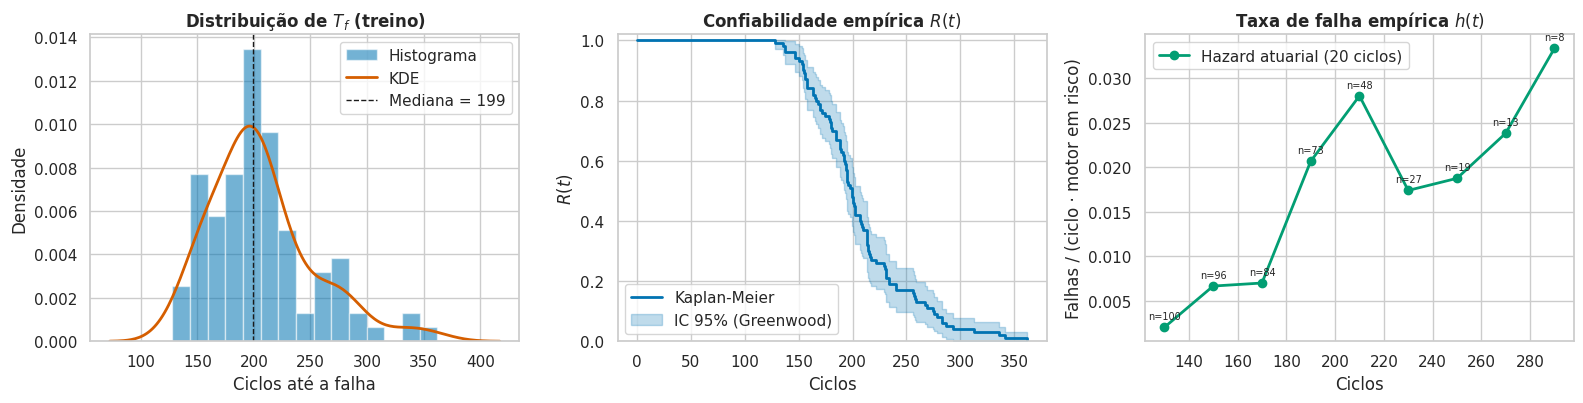

Hazard atuarial vai de 0.0020 (faixa 130) a 0.0333 (máximo); Spearman(t, h) = 0.82 → tendência crescente (desgaste).

In [ ]:
Tf = Tf_unit.values.astype(float)

def kaplan_meier(durations, events):
    d, e = np.asarray(durations, float), np.asarray(events, int)
    S, gw, rows = 1.0, 0.0, [(0.0, 1.0, 1.0, 1.0)]
    for t in np.unique(d[e == 1]):
        n = (d >= t).sum(); k = ((d == t) & (e == 1)).sum()
        S *= 1 - k / n
        if n > k:
            gw += k / (n * (n - k))
        se = S * np.sqrt(gw)
        rows.append((t, S, max(S - 1.96 * se, 0), min(S + 1.96 * se, 1)))
    return pd.DataFrame(rows, columns=["t", "S", "lo", "hi"])

def actuarial_hazard(T, width=20, start=120, min_risk=5):
    edges = np.arange(start, T.max() + width, width)
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        n = (T >= a).sum(); d = ((T >= a) & (T < b)).sum()
        if n >= min_risk:
            out.append(((a + b) / 2, d / ((n - d / 2) * (b - a)), n))
    return pd.DataFrame(out, columns=["t_mid", "h", "n_risco"])

km = kaplan_meier(Tf, np.ones_like(Tf))
haz = actuarial_hazard(Tf)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
axs[0].hist(Tf, bins=15, density=True, alpha=.55, color=PAL[0], label="Histograma")
sns.kdeplot(Tf, ax=axs[0], color=PAL[3], lw=2, label="KDE")
axs[0].axvline(np.median(Tf), ls="--", c="k", lw=1, label=f"Mediana = {np.median(Tf):.0f}")
axs[0].set(title="Distribuição de $T_f$ (treino)", xlabel="Ciclos até a falha", ylabel="Densidade"); axs[0].legend()
axs[1].step(km.t, km.S, where="post", color=PAL[0], lw=2, label="Kaplan-Meier")
axs[1].fill_between(km.t, km.lo, km.hi, step="post", alpha=.25, color=PAL[0], label="IC 95% (Greenwood)")
axs[1].set(title="Confiabilidade empírica $R(t)$", xlabel="Ciclos", ylabel="$R(t)$", ylim=(0, 1.02)); axs[1].legend()
axs[2].plot(haz.t_mid, haz.h, "o-", color=PAL[2], lw=2, label="Hazard atuarial (20 ciclos)")
for _, r in haz.iterrows():
    axs[2].annotate(f"n={int(r.n_risco)}", (r.t_mid, r.h), textcoords="offset points", xytext=(0, 6), fontsize=7, ha="center")
axs[2].set(title="Taxa de falha empírica $h(t)$", xlabel="Ciclos", ylabel="Falhas / (ciclo · motor em risco)"); axs[2].legend()
fig.tight_layout(); savefig(fig, "EDA1_Tf_KM_hazard")
rho_h = stats.spearmanr(haz.t_mid, haz.h)[0]
md_out(f"Hazard atuarial vai de {haz.h.iloc[0]:.4f} (faixa {haz.t_mid.iloc[0]:.0f}) a {haz.h.max():.4f} (máximo); Spearman(t, h) = {rho_h:.2f} → "
       f"{'tendência crescente (desgaste)' if rho_h > 0.3 else 'sem tendência clara'}.")

### 1.3 Figura EDA-2 — Degradação dos sensores e teto de RUL
Sensores top-6 normalizados (min-max do treino, orientados para crescer com a degradação), alinhados pelo RUL real (200 → 0), com **mediana** e banda interquartil da frota; linha vertical no teto de 125.

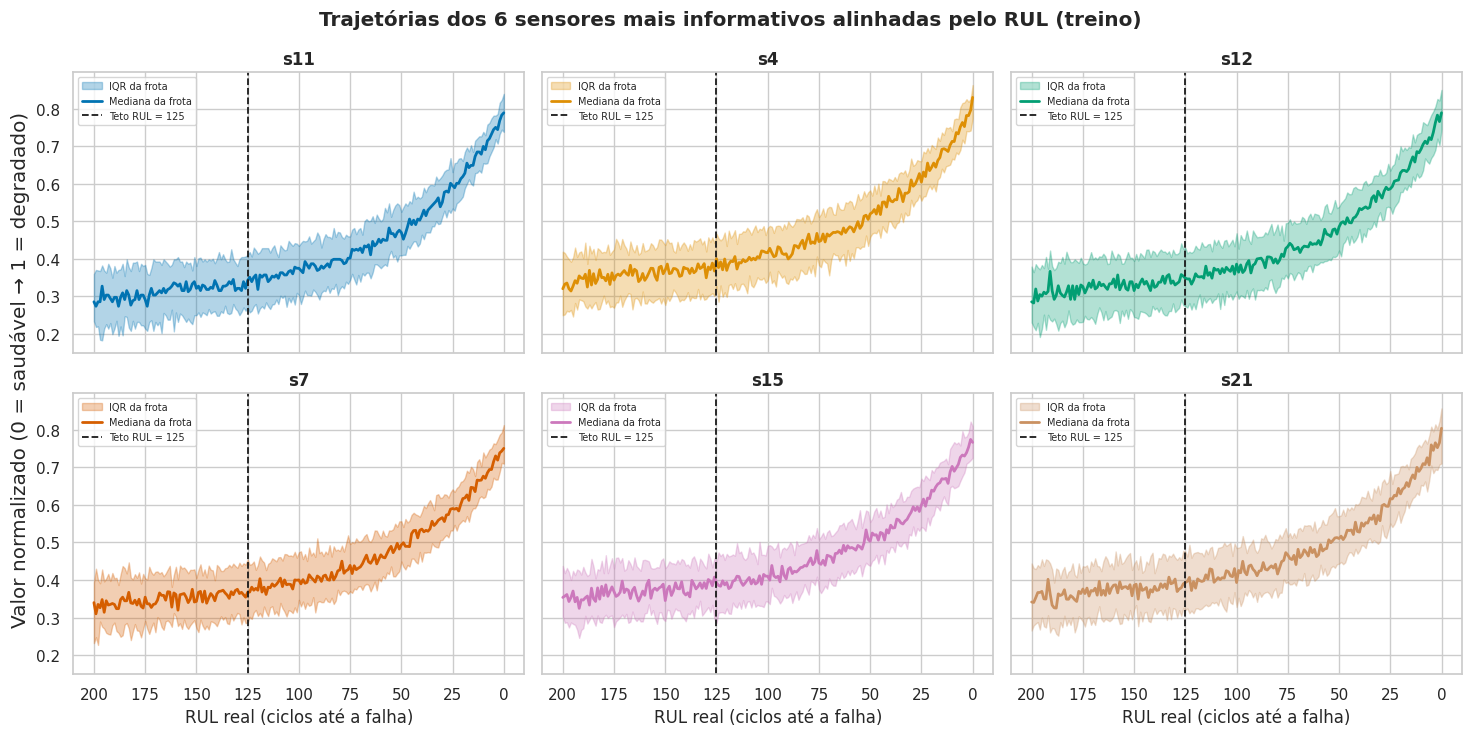

In [ ]:
def oriented_minmax(df, cols, ref):
    out = {}
    for c in cols:
        z = (df[c] - ref[c].min()) / (ref[c].max() - ref[c].min())
        out[c] = z if stats.spearmanr(ref[c], ref["cycle"])[0] > 0 else 1 - z
    return pd.DataFrame(out, index=df.index)

norm = oriented_minmax(train, TOP6, train)
norm["RUL"] = train["RUL"]
al = norm[norm.RUL <= 200]
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, sharey=True)
for ax, c, col in zip(axs.ravel(), TOP6, PAL):
    g = al.groupby("RUL")[c]
    q25, med, q75 = g.quantile(.25), g.median(), g.quantile(.75)
    ax.fill_between(med.index, q25, q75, color=col, alpha=.3, label="IQR da frota")
    ax.plot(med.index, med, color=col, lw=2, label="Mediana da frota")
    ax.axvline(RUL_CLIP, c="k", ls="--", lw=1.3, label=f"Teto RUL = {RUL_CLIP}")
    ax.set_title(c); ax.legend(fontsize=7)
axs[0, 0].invert_xaxis()
for ax in axs[-1]:
    ax.set_xlabel("RUL real (ciclos até a falha)")
fig.supylabel("Valor normalizado (0 = saudável → 1 = degradado)")
fig.suptitle("Trajetórias dos 6 sensores mais informativos alinhadas pelo RUL (treino)", fontweight="bold")
fig.tight_layout(); savefig(fig, "EDA2_trajetorias_knee")

### 1.4 Figura EDA-3 — Autocorrelação intra-motor
ACF de `s11`, `s4` e de um HI ilustrativo (PC1 do treino completo, apenas para visualização) em três motores representativos (vida curta, mediana e longa). A banda cinza é o IC 95% sob ruído branco para a série mais curta.

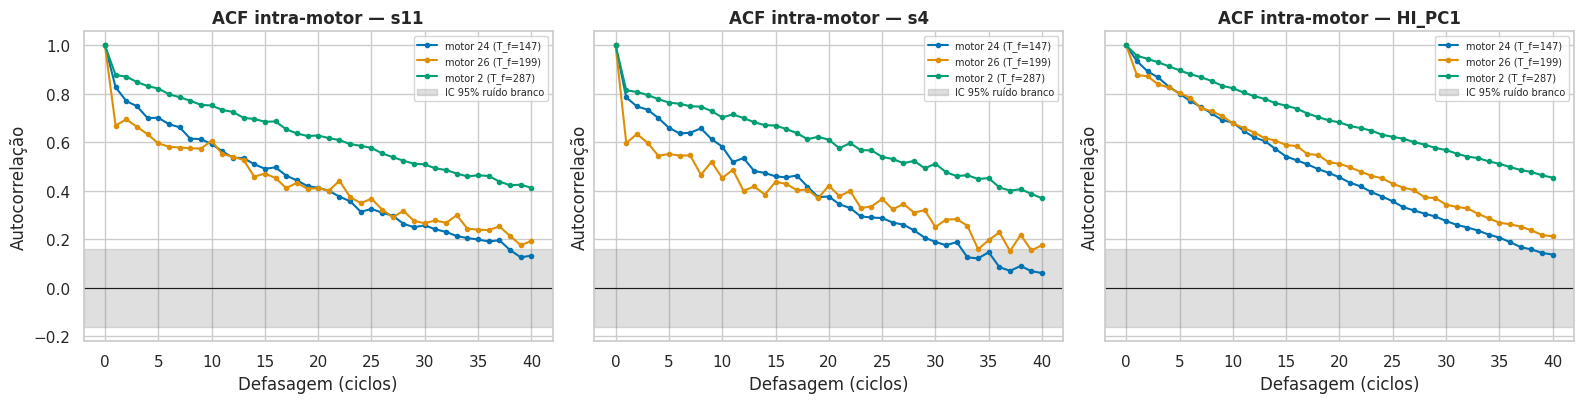

Defasagem em que a ACF cai abaixo de 0,5 (motores [24, 26, 2]): {'s11': [15, 14, 31], 's4': [13, 8, 29], 'HI_PC1': [18, 21, 36]}. Linhas consecutivas de um mesmo motor **não são independentes** → validação por `GroupKFold` por motor e inferência com **1 erro por motor**.

In [ ]:
z_all = StandardScaler().fit_transform(train[SENSORS])
pc = PCA(n_components=1, random_state=SEED).fit(z_all)
hi_vis = pc.transform(z_all)[:, 0]
hi_vis = hi_vis if np.corrcoef(hi_vis, train.cycle)[0, 1] > 0 else -hi_vis
train_vis = train[["unit_id", "cycle"] + SENSORS].assign(HI_PC1=hi_vis)

rep_units = [int(Tf_unit.index[np.argmin(np.abs(Tf_unit.values - np.quantile(Tf, q)))]) for q in (0.05, 0.5, 0.95)]
signals = ["s11", "s4", "HI_PC1"]
NLAGS = 40
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, sgn in zip(axs, signals):
    for u, col in zip(rep_units, PAL):
        x = train_vis.loc[train_vis.unit_id == u, sgn].values
        ax.plot(acf(x, nlags=NLAGS, fft=True), "o-", ms=3, color=col, label=f"motor {u} (T_f={Tf_unit[u]})")
    band = 1.96 / np.sqrt(Tf_unit[rep_units].min())
    ax.axhspan(-band, band, color="gray", alpha=.25, label="IC 95% ruído branco")
    ax.axhline(0, c="k", lw=.8)
    ax.set(title=f"ACF intra-motor — {sgn}", xlabel="Defasagem (ciclos)", ylabel="Autocorrelação"); ax.legend(fontsize=7)
fig.tight_layout(); savefig(fig, "EDA3_ACF_intra_motor")
lag05 = {s: [int(np.argmax(acf(train_vis.loc[train_vis.unit_id == u, s].values, nlags=NLAGS, fft=True) < .5)) for u in rep_units] for s in signals}
md_out(f"Defasagem em que a ACF cai abaixo de 0,5 (motores {rep_units}): {lag05}. Linhas consecutivas de um mesmo motor **não são independentes** → "
       "validação por `GroupKFold` por motor e inferência com **1 erro por motor**.")

<a id="s2"></a>
# Seção 2 — Pré-processamento, métricas e GroupKFold(5)

### 2.1 Alvo piecewise, folds fixos, snapshots OOF e último ciclo do teste
- `RUL_clip = min(RUL, 125)` é usado **somente como alvo de treino**.
- `GroupKFold(5)` por `unit_id` (balanceia nº de linhas entre folds). Em cada fold, 15% dos motores de treino formam a **validação interna** (early stopping).
- **Snapshots OOF:** 5 ciclos de corte por motor, uniformes em $[30, T_f]$ → 500 pontos de avaliação com RUL real conhecido.

In [ ]:
train["RUL_clip"] = train["RUL"].clip(upper=RUL_CLIP)
train["fold"] = -1
for k, (_, va_idx) in enumerate(GroupKFold(n_splits=N_FOLDS).split(train, groups=train["unit_id"])):
    train.loc[va_idx, "fold"] = k
FOLD_OF_UNIT = train.groupby("unit_id")["fold"].first()
assert (train.groupby("unit_id")["fold"].nunique() == 1).all() and (FOLD_OF_UNIT >= 0).all()

rng_split = np.random.default_rng(SEED)
FOLDS = []
for k in range(N_FOLDS):
    va_u = FOLD_OF_UNIT.index[FOLD_OF_UNIT == k].values
    tr_u = FOLD_OF_UNIT.index[FOLD_OF_UNIT != k].values
    inner = np.sort(rng_split.choice(tr_u, size=int(round(INNER_FRAC * len(tr_u))), replace=False))
    FOLDS.append({"val": va_u, "train": tr_u, "inner": inner, "fit": np.setdiff1d(tr_u, inner)})
    assert not set(va_u) & set(tr_u)

rng_cut = np.random.default_rng(SEED + 1)
cuts = [(u, int(c)) for u, T in Tf_unit.items() for c in np.sort(rng_cut.choice(np.arange(SEQ_LEN, T + 1), size=K_CUTS, replace=False))]
VAL_CUTS = (pd.DataFrame(cuts, columns=["unit_id", "cycle"])
            .merge(train[["unit_id", "cycle", "RUL", "fold"]].reset_index().rename(columns={"index": "row"}), on=["unit_id", "cycle"], how="left"))
Y_OOF = VAL_CUTS["RUL"].values.astype(float)

TEST_LAST = (test.groupby("unit_id").tail(1).reset_index().rename(columns={"index": "row"})[["unit_id", "cycle", "row"]]
             .sort_values("unit_id").reset_index(drop=True))
TEST_LAST["RUL"] = rul_test.loc[TEST_LAST.unit_id].values
Y_TEST = TEST_LAST["RUL"].values.astype(float)
M_LE, M_GT = Y_TEST <= RUL_CLIP, Y_TEST > RUL_CLIP
ELIG = (train["cycle"] >= SEQ_LEN).values
assert (VAL_CUTS.cycle >= SEQ_LEN).all() and (TEST_LAST.cycle >= SEQ_LEN).all() and VAL_CUTS.row.notna().all()

display(pd.DataFrame([{"fold": k, "motores val": len(F["val"]), "motores fit": len(F["fit"]), "motores val. interna": len(F["inner"]),
                       "linhas val": int((train.fold == k).sum()), "snapshots OOF": int((VAL_CUTS.fold == k).sum())} for k, F in enumerate(FOLDS)]).set_index("fold"))
print(f"Snapshots OOF: {len(VAL_CUTS)} | RUL real OOF: mediana {np.median(Y_OOF):.0f}, máx {Y_OOF.max():.0f} | "
      f"Teste: N={len(Y_TEST)}, RUL ≤ {RUL_CLIP}: {M_LE.sum()}, RUL > {RUL_CLIP}: {M_GT.sum()}")

,motores val,motores fit,motores val. interna,linhas val,snapshots OOF
fold,,,,,
0,20,68,12,4120,100
1,20,68,12,4133,100
2,20,68,12,4126,100
3,20,68,12,4125,100
4,20,68,12,4127,100


Snapshots OOF: 500 | RUL real OOF: mediana 84, máx 302 | Teste: N=100, RUL ≤ 125: 89, RUL > 125: 11


### 2.2 Métricas (1 erro por motor/snapshot)
$d_i = \widehat{\text{RUL}}_i - \text{RUL}_i$; NASA: $s_i = e^{-d_i/13}-1$ se $d_i<0$ e $e^{d_i/10}-1$ se $d_i\ge0$; predição **perigosa** = $d_i>0$ (atrasada).

In [ ]:
def nasa_terms(d):
    d = np.asarray(d, float)
    return np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(p, float) - np.asarray(y, float)) ** 2)))

def regression_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    d = p - y; s = nasa_terms(d)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return {"N": len(y), "MAE": float(np.mean(np.abs(d))), "RMSE": float(np.sqrt(np.mean(d ** 2))),
            "R2": float(1 - np.sum(d ** 2) / ss_tot) if ss_tot > 0 else np.nan,
            "NASA_total": float(s.sum()), "NASA_medio": float(s.mean()), "pct_perigosas": float(100 * np.mean(d > 0))}

# sanidade da NASA Score
assert np.isclose(nasa_terms([0.0])[0], 0) and nasa_terms([10.0])[0] > nasa_terms([-10.0])[0]
print("NASA s(-10) = %.3f | s(+10) = %.3f" % tuple(nasa_terms([-10.0, 10.0])))

NASA s(-10) = 1.158 | s(+10) = 1.718


### 2.3 Registro e avaliação padronizada de modelos
Todo modelo registra **(i)** predições OOF nos 500 snapshots e **(ii)** predições nos 100 motores de teste. Predições negativas são truncadas em 0. Utilitários de janela (`make_windows`) e de scaler por fold vivem aqui.

In [ ]:
REGISTRY = {}

def register(name, track, oof, test_pred, note=""):
    oof = np.maximum(np.asarray(oof, float), 0.0); tp = np.maximum(np.asarray(test_pred, float), 0.0)
    assert oof.shape == (len(VAL_CUTS),) and tp.shape == (len(TEST_LAST),), name
    assert np.isfinite(oof).all() and np.isfinite(tp).all(), f"{name}: predições não finitas"
    REGISTRY[name] = {"track": track, "oof": oof, "test": tp, "note": note}

def leaderboard(names=None):
    rows = []
    for n in (names or list(REGISTRY)):
        r = REGISTRY[n]; o = regression_metrics(Y_OOF, r["oof"]); t = regression_metrics(Y_TEST, r["test"])
        rows.append({"Modelo": n, "Trilha": r["track"], "RMSE OOF": o["RMSE"], "MAE OOF": o["MAE"], "NASA médio OOF": o["NASA_medio"],
                     "RMSE teste": t["RMSE"], "MAE teste": t["MAE"], "NASA total teste": t["NASA_total"], "% perigosas teste": t["pct_perigosas"]})
    return pd.DataFrame(rows).set_index("Modelo")

def fold_scaler(k):
    """StandardScaler ajustado SOMENTE nos motores de treino do fold k."""
    return StandardScaler().fit(train.loc[train.unit_id.isin(FOLDS[k]["train"]), SENSORS])

WIN_OFFSETS = np.arange(-SEQ_LEN + 1, 1)
def make_windows(X, end_rows):
    """Janelas (N, SEQ_LEN, n_feat) terminando em end_rows; válidas pois ciclo ≥ SEQ_LEN e ciclos são contíguos por motor."""
    return np.ascontiguousarray(X[np.asarray(end_rows, int)[:, None] + WIN_OFFSETS[None, :]])

# checagem de integridade das janelas: todas as linhas de cada janela pertencem ao mesmo motor
_u = train.unit_id.values[np.asarray(VAL_CUTS.row, int)[:, None] + WIN_OFFSETS[None, :]]
assert (_u == _u[:, [-1]]).all()

<a id="s3"></a>
# Seção 3 — Trilha A: modelos probabilísticos de confiabilidade

## A1. Tempo até a falha → Mean Residual Life
$\widehat{\text{RUL}}_i=\text{MRL}(t_i)=\int_{t_i}^{\infty}R(u)\,du\,/\,R(t_i)$, com $R$ = `dist.sf` (nunca `1 - cdf`) e `integrate.quad` até `np.inf`. Para a Weibull 3P, se $t_i\le\gamma$ então $R(t_i)=1$ e $\text{MRL}=E[T_f]-t_i$ (tratado explicitamente). OOF: distribuições ajustadas nos $T_f$ do treino de cada fold; teste: ajuste no treino completo.

In [ ]:
def fit_lifetime_models(T):
    T = np.asarray(T, float)
    fits = {"Weibull2P": (stats.weibull_min, stats.weibull_min.fit(T, floc=0)),
            "Lognormal": (stats.lognorm, stats.lognorm.fit(T, floc=0))}
    prm = stats.weibull_min.fit(T)
    if not (0 < prm[1] < T.min()):
        warnings.warn(f"Weibull 3P: loc={prm[1]:.2f} fora de (0, min T_f={T.min():.0f}); reajuste com chute inicial.")
        c0, _, s0 = stats.weibull_min.fit(T - 0.9 * T.min(), floc=0)
        prm = stats.weibull_min.fit(T, c0, loc=0.9 * T.min(), scale=s0)
    fits["Weibull3P"] = (stats.weibull_min, prm)
    return fits

def mrl(dist, prm, t):
    loc = prm[-2]
    if t <= loc:                                   # antes do início do suporte: R(t) = 1
        return float(dist.mean(*prm) - t)
    R = dist.sf(t, *prm)
    if R < 1e-12:                                  # cauda extrema: vida residual desprezível
        return 0.0
    val, _ = integrate.quad(lambda u: dist.sf(u, *prm), t, np.inf, limit=200)
    return float(val / R)

def mrl_vec(dist, prm, ts):
    ts = np.asarray(ts, float)
    lut = {t: mrl(dist, prm, t) for t in np.unique(ts)}
    return np.array([lut[t] for t in ts])

A1_NAMES = ["Weibull2P", "Lognormal", "Weibull3P"]
A1_OOF = {m: np.zeros(len(VAL_CUTS)) for m in A1_NAMES}
fold_params = []
for k, F in enumerate(FOLDS):
    fits_k = fit_lifetime_models(Tf_unit.loc[F["train"]].values)
    idx = (VAL_CUTS.fold == k).values
    for m, (dist, prm) in fits_k.items():
        A1_OOF[m][idx] = mrl_vec(dist, prm, VAL_CUTS.cycle.values[idx])
        fold_params.append({"fold": k, "modelo": m, "params (shape, loc, scale)": tuple(np.round(prm, 3))})
display(pd.DataFrame(fold_params).pivot(index="fold", columns="modelo", values="params (shape, loc, scale)"))

A1_FITS = fit_lifetime_models(Tf)          # treino completo → teste
for m, (dist, prm) in A1_FITS.items():
    register(f"A1-{m}", "A", A1_OOF[m], mrl_vec(dist, prm, TEST_LAST.cycle.values), note="MRL(t_i) populacional")

/tmp/ipykernel_947/58844046.py:7: UserWarning: Weibull 3P: loc=133.96 fora de (0, min T_f=128); reajuste com chute inicial.
  warnings.warn(f"Weibull 3P: loc={prm[1]:.2f} fora de (0, min T_f={T.min():.0f}); reajuste com chute inicial.")
/tmp/ipykernel_947/58844046.py:7: UserWarning: Weibull 3P: loc=145.66 fora de (0, min T_f=128); reajuste com chute inicial.
  warnings.warn(f"Weibull 3P: loc={prm[1]:.2f} fora de (0, min T_f={T.min():.0f}); reajuste com chute inicial.")
/tmp/ipykernel_947/58844046.py:7: UserWarning: Weibull 3P: loc=145.66 fora de (0, min T_f=128); reajuste com chute inicial.
  warnings.warn(f"Weibull 3P: loc={prm[1]:.2f} fora de (0, min T_f={T.min():.0f}); reajuste com chute inicial.")


modelo,Lognormal,Weibull2P,Weibull3P
fold,,,
0,"(0.209, 0.0, 201.805)","(4.571, 0.0, 224.853)","(1.7, 131.415, 83.924)"
1,"(0.213, 0.0, 201.492)","(4.43, 0.0, 224.9)","(1.844, 124.425, 92.045)"
2,"(0.212, 0.0, 201.599)","(4.412, 0.0, 225.013)","(1.841, 124.827, 91.731)"
3,"(0.213, 0.0, 201.565)","(4.345, 0.0, 225.148)","(1.823, 124.893, 91.627)"
4,"(0.214, 0.0, 201.498)","(4.311, 0.0, 225.213)","(1.809, 124.996, 91.454)"


In [ ]:
rows = []
for m, (dist, prm) in A1_FITS.items():
    k_par = 3 if m == "Weibull3P" else 2
    ll = dist.logpdf(Tf, *prm).sum()
    if m == "Lognormal":
        pstr = f"σ={prm[0]:.4f}, μ=ln(scale)={np.log(prm[2]):.4f}"
    elif m == "Weibull3P":
        pstr = f"β={prm[0]:.3f}, η={prm[2]:.2f}, γ(loc)={prm[1]:.2f}"
    else:
        pstr = f"β={prm[0]:.3f}, η={prm[2]:.2f}"
    rows.append({"Modelo": m, "Parâmetros (treino completo)": pstr, "logL": ll, "AIC": 2 * k_par - 2 * ll,
                 "BIC": k_par * np.log(len(Tf)) - 2 * ll, "E[T_f]": dist.mean(*prm)})
A1_PARAMS = pd.DataFrame(rows).set_index("Modelo")
display(A1_PARAMS); save_table(A1_PARAMS.drop(columns="Parâmetros (treino completo)"), "A1_parametros")
display(leaderboard([f"A1-{m}" for m in A1_NAMES]))

,Parâmetros (treino completo),logL,AIC,BIC,E[T_f]
Modelo,,,,,
Weibull2P,"β=4.409, η=225.03",-530.7489,"1,065.4979","1,070.7082",205.1086
Lognormal,"σ=0.2121, μ=ln(scale)=5.3062",-517.4560,"1,038.9120","1,044.1223",206.1783
Weibull3P,"β=1.830, η=91.29, γ(loc)=125.19",-516.5162,"1,039.0325","1,046.8480",206.3156


,Trilha,RMSE OOF,MAE OOF,NASA médio OOF,RMSE teste,MAE teste,NASA total teste,% perigosas teste
Modelo,,,,,,,,
A1-Weibull2P,A,43.1564,34.1748,"1,109.3746",37.7995,32.3562,"10,521.4273",65.0000
A1-Lognormal,A,42.0432,32.5993,"1,195.2086",37.1191,31.6483,"8,438.9843",66.0000
A1-Weibull3P,A,42.0523,32.7505,"1,170.8048",37.0381,31.7256,"7,986.1167",66.0000


**Figura A1 — MRL teórica × RUL real do teste.** Cada ponto é um motor de teste $(t_i,\text{RUL}_i)$; as curvas são o que cada modelo sem sensores consegue prever em função apenas da idade.

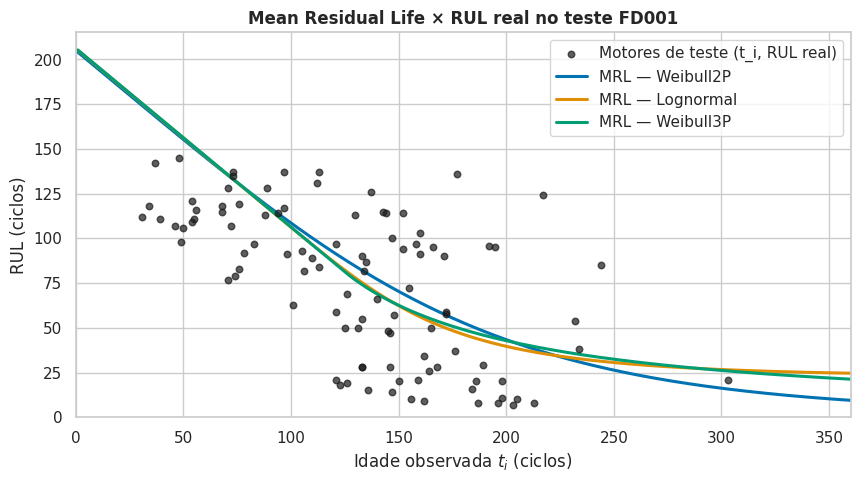

,n,RUL_real_dp,RUL_real_amplitude,MRL_dp
idade,,,,
"(30.999, 88.75]",25,17.9111,68.0000,16.2462
"(88.75, 133.5]",25,38.4449,119.0000,13.3541
"(133.5, 164.25]",25,39.1354,117.0000,6.2774
"(164.25, 303.0]",25,39.3873,129.0000,7.1910


Melhor A1 no OOF: **A1-Lognormal**. Dentro de cada quartil de idade, o RUL real varia com desvio-padrão médio de **33.7 ciclos**, enquanto a MRL varia só 10.8 ciclos: um modelo apenas de idade não separa motores que degradam rápido dos que degradam devagar na mesma idade — limite que motiva os modelos com sensores.

In [ ]:
t_grid = np.arange(1, 361)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(TEST_LAST.cycle, Y_TEST, s=22, c="k", alpha=.7, label="Motores de teste (t_i, RUL real)", zorder=3)
for (m, (dist, prm)), col in zip(A1_FITS.items(), PAL):
    ax.plot(t_grid, mrl_vec(dist, prm, t_grid), lw=2.2, color=col, label=f"MRL — {m}")
ax.set(title="Mean Residual Life × RUL real no teste FD001", xlabel="Idade observada $t_i$ (ciclos)", ylabel="RUL (ciclos)", xlim=(0, 360), ylim=(0, None))
ax.legend(); savefig(fig, "A1_MRL_vs_RUL_teste")

bins = pd.qcut(TEST_LAST.cycle, 4)
spread = pd.DataFrame({"idade": bins, "RUL": Y_TEST, "MRL_Lognormal": REGISTRY["A1-Lognormal"]["test"]}).groupby("idade", observed=True).agg(
    n=("RUL", "size"), RUL_real_dp=("RUL", "std"), RUL_real_amplitude=("RUL", lambda s: s.max() - s.min()), MRL_dp=("MRL_Lognormal", "std"))
display(spread)
best_a1 = leaderboard([f"A1-{m}" for m in A1_NAMES])["RMSE OOF"].idxmin()
md_out(f"Melhor A1 no OOF: **{best_a1}**. Dentro de cada quartil de idade, o RUL real varia com desvio-padrão médio de "
       f"**{spread.RUL_real_dp.mean():.1f} ciclos**, enquanto a MRL varia só {spread.MRL_dp.mean():.1f} ciclos: um modelo apenas de idade "
       "não separa motores que degradam rápido dos que degradam devagar na mesma idade — limite que motiva os modelos com sensores.")

## A2. Processo de Wiener sobre Health Index
**HI** ajustado só no treino de cada fold: **HI-PCA** (PC1 dos 14 sensores padronizados, orientado para crescer com o ciclo) e **HI-Ridge** (Ridge dos sensores padronizados contra $D(t)=1-\text{RUL}_{clip}/125$). Ambos suavizados por **EWMA causal** por motor (`adjust=False`, sem olhar o futuro).

**Wiener com deriva linear** $X(t)=X_0+\mu t+\sigma B(t)$ estimado na fase ativa ($\text{RUL}\le125$) com $\Delta t=1$: $\hat\mu=\overline{\Delta HI}$, $\hat\sigma=\text{dp}(\Delta HI)$; limiar $w$ = mediana de $HI(T_f)$. Predição: $\widehat{\text{RUL}}=\max(0,(w-HI(t_i))/\mu)$ = média do tempo de primeira passagem (Gaussiana Inversa).
**Variante Bayesiana:** deriva individual com prior $\mathcal N(\mu_0,\sigma_\mu^2)$ (inclinações por motor no treino) e verossimilhança da deriva observada nos últimos 30 ciclos (precisão $L/\sigma^2$); piso de 20% da deriva populacional.
*Limitações declaradas:* a degradação é convexa (deriva linear é aproximação) e a EWMA induz correlação nos incrementos (σ tende a ser subestimado → IC estreitos; a cobertura é medida no teste).

In [ ]:
def ewm_by_unit(values, units, span=HI_EWM_SPAN):
    return pd.Series(np.asarray(values, float)).groupby(np.asarray(units)).transform(lambda s: s.ewm(span=span, adjust=False).mean()).values

class HealthIndex:
    """HI ajustado SOMENTE nas linhas recebidas em fit (scaler + PCA ou Ridge)."""
    def __init__(self, kind):
        assert kind in ("pca", "ridge"); self.kind = kind
    def fit(self, df_fit):
        self.scaler = StandardScaler().fit(df_fit[SENSORS])
        Z = self.scaler.transform(df_fit[SENSORS])
        if self.kind == "pca":
            self.model = PCA(n_components=1, random_state=SEED).fit(Z)
            raw = self.model.transform(Z)[:, 0]
            self.sign = 1.0 if np.corrcoef(raw, df_fit["cycle"])[0, 1] >= 0 else -1.0
        else:
            self.model = Ridge(alpha=1.0).fit(Z, 1.0 - df_fit["RUL_clip"].values / RUL_CLIP)
            self.sign = 1.0
        return self
    def raw(self, df):
        Z = self.scaler.transform(df[SENSORS])
        return self.sign * (self.model.transform(Z)[:, 0] if self.kind == "pca" else self.model.predict(Z))
    def smooth(self, df):
        return ewm_by_unit(self.raw(df), df["unit_id"].values)

def fit_wiener(hi_s, df_fit):
    """hi_s alinhado com df_fit (motores completos, ordenados por ciclo)."""
    u = df_fit["unit_id"].values
    inc = np.diff(hi_s, prepend=np.nan)
    inc[np.r_[True, u[1:] != u[:-1]]] = np.nan
    active = (df_fit["RUL"].values <= RUL_CLIP)
    ok = active & ~np.isnan(inc)
    mu, sigma = float(np.mean(inc[ok])), float(np.std(inc[ok], ddof=1))
    last = df_fit.groupby("unit_id").cumcount(ascending=False).values == 0
    act = pd.DataFrame({"u": u, "c": df_fit["cycle"].values.astype(float), "h": hi_s})[active]
    cm = act.groupby("u")["c"].transform("mean"); hm = act.groupby("u")["h"].transform("mean")
    slopes = ((act.c - cm) * (act.h - hm)).groupby(act.u).sum() / ((act.c - cm) ** 2).groupby(act.u).sum()
    prm = {"mu": mu, "sigma": sigma, "w": float(np.median(hi_s[last])), "mu0": float(slopes.mean()), "s_mu": float(slopes.std(ddof=1))}
    assert prm["mu"] > 0 and prm["sigma"] > 0, f"Deriva/difusão inválidas: {prm}"
    return prm

def wiener_predict(hi_s, rows, cycles, prm, bayes=False, L=WIENER_LAST):
    rows = np.asarray(rows, int); hi_now = hi_s[rows]
    if bayes:
        Leff = np.minimum(L, np.asarray(cycles, int) - 1)
        obs = (hi_now - hi_s[rows - Leff]) / Leff
        prec0, prec_obs = 1.0 / prm["s_mu"] ** 2, Leff / prm["sigma"] ** 2
        mu = (prm["mu0"] * prec0 + obs * prec_obs) / (prec0 + prec_obs)
    else:
        mu = np.full(len(rows), prm["mu"])
    mu = np.maximum(mu, MU_FLOOR_FRAC * prm["mu"])
    return np.maximum(0.0, (prm["w"] - hi_now) / mu), mu, hi_now

### A2.1 Comparação HI-PCA × HI-Ridge em GroupKFold(5) (seleção pelo RMSE OOF do Wiener populacional)

In [ ]:
A2_OOF, HI_QUALITY = {}, []
for kind in ("pca", "ridge"):
    oof_pop, oof_bay = np.zeros(len(VAL_CUTS)), np.zeros(len(VAL_CUTS))
    for k, F in enumerate(FOLDS):
        fit_mask = train.unit_id.isin(F["train"]).values
        hi = HealthIndex(kind).fit(train[fit_mask])
        hs_all = hi.smooth(train)                          # EWMA causal por motor
        prm = fit_wiener(hs_all[fit_mask], train[fit_mask])
        idx = (VAL_CUTS.fold == k).values
        rows_k, cyc_k = VAL_CUTS.row.values[idx], VAL_CUTS.cycle.values[idx]
        oof_pop[idx] = wiener_predict(hs_all, rows_k, cyc_k, prm)[0]
        oof_bay[idx] = wiener_predict(hs_all, rows_k, cyc_k, prm, bayes=True)[0]
        va = (train.fold == k).values
        HI_QUALITY.append({"HI": kind, "fold": k, "Spearman(HI, RUL_clip) val": stats.spearmanr(hs_all[va], train.RUL_clip.values[va])[0],
                           "μ": prm["mu"], "σ": prm["sigma"], "μ/σ": prm["mu"] / prm["sigma"], "w": prm["w"]})
    A2_OOF[(kind, "pop")], A2_OOF[(kind, "bayes")] = oof_pop, oof_bay

hiq = pd.DataFrame(HI_QUALITY)
display(hiq.groupby("HI")[["Spearman(HI, RUL_clip) val", "μ/σ"]].agg(["mean", "std"]))
cmp_hi = pd.DataFrame({f"{kind}-{var}": regression_metrics(Y_OOF, p) for (kind, var), p in A2_OOF.items()}).T[["RMSE", "MAE", "NASA_medio", "pct_perigosas"]]
display(cmp_hi)
BEST_HI = min(("pca", "ridge"), key=lambda kd: rmse(Y_OOF, A2_OOF[(kd, "pop")]))
md_out(f"HI escolhido pelo RMSE OOF do Wiener populacional: **HI-{BEST_HI.upper()}** "
       f"(RMSE OOF pop = {rmse(Y_OOF, A2_OOF[(BEST_HI, 'pop')]):.2f}; Bayes = {rmse(Y_OOF, A2_OOF[(BEST_HI, 'bayes')]):.2f}). "
       f"Spearman médio HI×RUL_clip na validação: PCA {hiq[hiq.HI == 'pca']['Spearman(HI, RUL_clip) val'].mean():.3f}, "
       f"Ridge {hiq[hiq.HI == 'ridge']['Spearman(HI, RUL_clip) val'].mean():.3f}.")

Spearman(HI, RUL_clip) val           μ/σ       
                            mean    std   mean    std
HI                                                   
pca                      -0.7634 0.0276 0.5822 0.0062
ridge                    -0.8024 0.0272 0.6364 0.0069

,RMSE,MAE,NASA_medio,pct_perigosas
pca-pop,42.1060,33.6274,"1,697.6193",69.6000
pca-bayes,51.6920,43.5469,"1,863.2827",88.0000
ridge-pop,39.6052,30.1894,"2,737.8810",63.2000
ridge-bayes,50.5864,42.8244,"2,278.1416",88.4000


HI escolhido pelo RMSE OOF do Wiener populacional: **HI-RIDGE** (RMSE OOF pop = 39.61; Bayes = 50.59). Spearman médio HI×RUL_clip na validação: PCA -0.763, Ridge -0.802.

### A2.2 Ajuste final no treino completo e predição no teste

In [ ]:
HI_FINAL = HealthIndex(BEST_HI).fit(train)
hs_train = HI_FINAL.smooth(train)
WIENER = fit_wiener(hs_train, train)
hs_test = HI_FINAL.smooth(test)
rul_pop, mu_pop, hi_now_test = wiener_predict(hs_test, TEST_LAST.row.values, TEST_LAST.cycle.values, WIENER)
rul_bay, mu_bay, _ = wiener_predict(hs_test, TEST_LAST.row.values, TEST_LAST.cycle.values, WIENER, bayes=True)
register("A2-Wiener-pop", "A", A2_OOF[(BEST_HI, "pop")], rul_pop, note=f"HI-{BEST_HI}, deriva populacional")
register("A2-Wiener-bayes", "A", A2_OOF[(BEST_HI, "bayes")], rul_bay, note=f"HI-{BEST_HI}, deriva individual Bayesiana")
display(pd.Series(WIENER, name=f"Wiener (HI-{BEST_HI}, treino completo)").to_frame())
display(leaderboard(["A2-Wiener-pop", "A2-Wiener-bayes"]))

,"Wiener (HI-ridge, treino completo)"
mu,0.0066
sigma,0.0104
w,0.9267
mu0,0.0059
s_mu,0.0012


,Trilha,RMSE OOF,MAE OOF,NASA médio OOF,RMSE teste,MAE teste,NASA total teste,% perigosas teste
Modelo,,,,,,,,
A2-Wiener-pop,A,39.6052,30.1894,"2,737.8810",25.8700,20.7514,"3,294.1892",75.0000
A2-Wiener-bayes,A,50.5864,42.8244,"2,278.1416",51.8792,44.5150,"1,156,129.0398",97.0000


### A2.3 Distribuição do RUL (Gaussiana Inversa) e IC 95%
Com distância remanescente $\delta=w-HI(t_i)>0$: $T\sim IG(m=\delta/\mu,\ \lambda=\delta^2/\sigma^2)$ (em SciPy: `invgauss(mu=m/λ, scale=λ)`). Mostram-se 4 motores representativos e a **cobertura empírica** dos IC 95% nos 100 motores de teste.

,cobertura_IC95,largura_mediana
pop,0.6400,60.0703
bayes,0.3900,95.1667


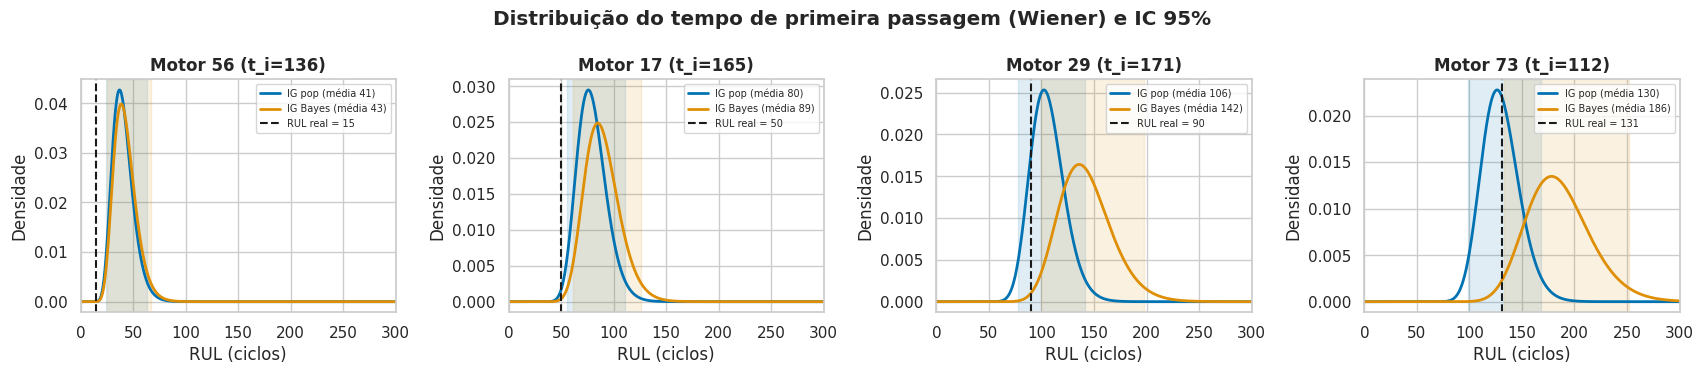

Cobertura empírica dos IC 95% no teste: populacional **64%**, Bayesiano **39%** (ideal ≈ 95%). Cobertura abaixo do nominal indica σ subestimado (efeito da EWMA/deriva linear).

In [ ]:
def fpt_dist(delta, mu, sigma):
    m, lam = delta / mu, delta ** 2 / sigma ** 2
    return stats.invgauss(mu=m / lam, scale=lam)

def ig_interval(delta, mu, sigma, level=0.95):
    lo, hi = np.zeros(len(delta)), np.zeros(len(delta))
    pos = delta > 0
    for i in np.where(pos)[0]:
        dd = fpt_dist(delta[i], mu[i], sigma)
        lo[i], hi[i] = dd.ppf((1 - level) / 2), dd.ppf(1 - (1 - level) / 2)
    return lo, hi

delta_test = WIENER["w"] - hi_now_test
COVERAGE = {}
for lbl, mu_v in (("pop", mu_pop), ("bayes", mu_bay)):
    lo, hi_ = ig_interval(delta_test, mu_v, WIENER["sigma"])
    COVERAGE[lbl] = {"cobertura_IC95": float(np.mean((Y_TEST >= lo) & (Y_TEST <= hi_))), "largura_mediana": float(np.median(hi_ - lo))}
display(pd.DataFrame(COVERAGE).T)

targets = (15, 50, 90, 130)
rep_test = list(dict.fromkeys(int(np.argmin(np.abs(Y_TEST - r))) for r in targets))
x = np.linspace(0.5, 400, 800)
fig, axs = plt.subplots(1, len(rep_test), figsize=(4.3 * len(rep_test), 3.8))
for ax, i in zip(np.atleast_1d(axs), rep_test):
    for lbl, mu_v, col in (("pop", mu_pop, PAL[0]), ("Bayes", mu_bay, PAL[1])):
        if delta_test[i] <= 0:
            continue
        dd = fpt_dist(delta_test[i], mu_v[i], WIENER["sigma"])
        ax.plot(x, dd.pdf(x), color=col, lw=2, label=f"IG {lbl} (média {dd.mean():.0f})")
        lo, hi_ = dd.ppf([.025, .975]); ax.axvspan(lo, hi_, color=col, alpha=.12)
    ax.axvline(Y_TEST[i], c="k", ls="--", lw=1.5, label=f"RUL real = {Y_TEST[i]:.0f}")
    ax.set(title=f"Motor {TEST_LAST.unit_id[i]} (t_i={TEST_LAST.cycle[i]})", xlabel="RUL (ciclos)", ylabel="Densidade", xlim=(0, 300))
    ax.legend(fontsize=7)
fig.suptitle("Distribuição do tempo de primeira passagem (Wiener) e IC 95%", fontweight="bold")
fig.tight_layout(); savefig(fig, "A2_IG_densidades")
md_out(f"Cobertura empírica dos IC 95% no teste: populacional **{COVERAGE['pop']['cobertura_IC95']:.0%}**, Bayesiano **{COVERAGE['bayes']['cobertura_IC95']:.0%}** "
       f"(ideal ≈ 95%). " + ("Cobertura abaixo do nominal indica σ subestimado (efeito da EWMA/deriva linear)." if min(v['cobertura_IC95'] for v in COVERAGE.values()) < 0.9 else
       "Cobertura próxima do nominal."))

<a id="s4"></a>
# Seção 4 — Trilha B: Machine Learning e Deep Learning (GPU)

## B1. XGBoost com features temporais causais
Por fold: `StandardScaler` + HI-PCA ajustados no treino do fold; features por motor com janelas $w\in\{5,15,30\}$ sobre 14 sensores + HI: valor atual, média, desvio, **inclinação OLS** (fechada por médias móveis de $t$, $t^2$, $tx$) e diferença ao início da janela — tudo com `rolling`/`shift` **causais** (só ciclos ≤ atual). Early stopping na validação interna; tuning por busca aleatória controlada, selecionando pelo RMSE médio de validação (alvo com teto) nos 5 folds.

In [ ]:
def causal_features(df, cols, windows=XGB_WINDOWS):
    """df ordenado por (unit_id, cycle) com RangeIndex; usa apenas o passado de cada motor."""
    out = {f"{c}_cur": df[c].values for c in cols}
    t = df["cycle"].astype(float)
    aux = df[["unit_id"] + cols].copy()
    aux["_t"], aux["_t2"] = t, t ** 2
    for c in cols:
        aux[f"_tx_{c}"] = t * df[c]
    g = aux.groupby("unit_id", sort=False)
    first = g[cols].transform("first")
    for w in windows:
        m = g.rolling(w, min_periods=1).mean().reset_index(level=0, drop=True).sort_index()
        sd = g[cols].rolling(w, min_periods=2).std().reset_index(level=0, drop=True).sort_index().fillna(0.0)
        start = g[cols].shift(w - 1).fillna(first)
        var_t = (m["_t2"] - m["_t"] ** 2).where(lambda v: v > 1e-9)
        for c in cols:
            out[f"{c}_mean{w}"] = m[c].values
            out[f"{c}_std{w}"] = sd[c].values
            out[f"{c}_slope{w}"] = ((m[f"_tx_{c}"] - m["_t"] * m[c]) / var_t).fillna(0.0).values
            out[f"{c}_diff{w}"] = (df[c] - start[c]).values
    return pd.DataFrame(out, index=df.index).astype(np.float32)

FEAT_SRC = SENSORS + ["HI"]
def fold_feature_frames(k):
    hi = HealthIndex("pca").fit(train[train.unit_id.isin(FOLDS[k]["train"])])   # scaler + PCA só no treino do fold
    def prep(df):
        z = pd.DataFrame(hi.scaler.transform(df[SENSORS]), columns=SENSORS, index=df.index)
        z.insert(0, "unit_id", df["unit_id"].values); z.insert(1, "cycle", df["cycle"].values)
        z["HI"] = hi.raw(df)
        return causal_features(z, FEAT_SRC)
    return prep(train), prep(test)

t0 = time.time()
FEAT = {k: fold_feature_frames(k) for k in range(N_FOLDS)}
print(f"Features por fold: {FEAT[0][0].shape[1]} colunas | treino {FEAT[0][0].shape[0]:,} linhas | teste {FEAT[0][1].shape[0]:,} | {time.time() - t0:.1f}s")

Features por fold: 195 colunas | treino 20,631 linhas | teste 13,096 | 6.2s


In [ ]:
def xgb_predict(model, X):
    model.get_booster().set_param({"device": "cpu"})   # predição em CPU (dados em numpy, evita cópia device↔host)
    return model.predict(X)

def xgb_cv(params, clip=RUL_CLIP, keep=False):
    y = np.minimum(train["RUL"].values, clip).astype(np.float32)
    res = {"rmse_val": [], "best_iter": [], "oof_rows": np.full(len(train), np.nan), "test": [], "models": []}
    for k, F in enumerate(FOLDS):
        Xtr, Xte = FEAT[k]
        m_fit, m_in = train.unit_id.isin(F["fit"]).values, train.unit_id.isin(F["inner"]).values
        m_va = (train.fold == k).values
        model = xgb.XGBRegressor(n_estimators=XGB_MAX_ROUNDS, early_stopping_rounds=XGB_EARLY_STOP, eval_metric="rmse",
                                 tree_method="hist", device=XGB_DEVICE, random_state=SEED, **params)
        model.fit(Xtr[m_fit], y[m_fit], eval_set=[(Xtr[m_in], y[m_in])], verbose=False)
        p_va = xgb_predict(model, Xtr[m_va])
        res["rmse_val"].append(rmse(y[m_va], p_va)); res["best_iter"].append(int(model.best_iteration))
        if keep:
            res["oof_rows"][m_va] = p_va
            res["test"].append(xgb_predict(model, Xte.iloc[TEST_LAST.row.values]))
            res["models"].append(model)
    res["rmse_mean"] = float(np.mean(res["rmse_val"]))
    if keep:
        res["oof"] = res["oof_rows"][VAL_CUTS.row.values]
        res["test_mean"] = np.mean(res["test"], axis=0)
    return res

XGB_BASE = {"max_depth": 6, "learning_rate": 0.03, "subsample": 0.8, "colsample_bytree": 0.8,
            "min_child_weight": 5.0, "reg_alpha": 0.0, "reg_lambda": 1.0}
rng_tune = np.random.default_rng(SEED)
def sample_xgb_params():
    return {"max_depth": int(rng_tune.integers(3, 9)), "learning_rate": float(10 ** rng_tune.uniform(-2.0, -0.9)),
            "subsample": float(rng_tune.uniform(0.6, 1.0)), "colsample_bytree": float(rng_tune.uniform(0.4, 1.0)),
            "min_child_weight": float(10 ** rng_tune.uniform(0, 1.5)), "reg_alpha": float(10 ** rng_tune.uniform(-3, 1)),
            "reg_lambda": float(10 ** rng_tune.uniform(-1, 1.5))}

In [ ]:
trials = []
for i in range(XGB_N_TRIALS):
    p = dict(XGB_BASE) if i == 0 else sample_xgb_params()
    t0 = time.time(); r = xgb_cv(p)
    trials.append({**p, "RMSE_val_cv": r["rmse_mean"], "dp_folds": float(np.std(r["rmse_val"])),
                   "best_iter_mediano": float(np.median(r["best_iter"])), "seg": time.time() - t0})
    print(f"trial {i:02d} | RMSE cv = {r['rmse_mean']:.3f} | {time.time() - t0:.1f}s")
XGB_TUNING = pd.DataFrame(trials).sort_values("RMSE_val_cv").reset_index(drop=True)
display(XGB_TUNING.head(10)); save_table(XGB_TUNING, "B1_xgb_tuning", index=False)
XGB_BEST = {k: (int(XGB_TUNING.loc[0, k]) if k == "max_depth" else float(XGB_TUNING.loc[0, k])) for k in XGB_BASE}
print("Melhores hiperparâmetros:", XGB_BEST)

trial 00 | RMSE cv = 12.342 | 11.9s
trial 01 | RMSE cv = 12.576 | 12.0s
trial 02 | RMSE cv = 12.413 | 9.8s
trial 03 | RMSE cv = 12.312 | 11.3s
trial 04 | RMSE cv = 12.462 | 9.0s
trial 05 | RMSE cv = 12.237 | 19.3s
trial 06 | RMSE cv = 12.242 | 10.9s
trial 07 | RMSE cv = 12.339 | 12.3s
trial 08 | RMSE cv = 12.301 | 16.3s
trial 09 | RMSE cv = 12.480 | 11.1s
trial 10 | RMSE cv = 12.286 | 24.1s
trial 11 | RMSE cv = 12.262 | 9.3s
trial 12 | RMSE cv = 12.376 | 5.9s
trial 13 | RMSE cv = 12.614 | 8.6s
trial 14 | RMSE cv = 12.287 | 19.9s
trial 15 | RMSE cv = 12.266 | 9.6s
trial 16 | RMSE cv = 12.435 | 26.6s
trial 17 | RMSE cv = 12.344 | 5.9s
trial 18 | RMSE cv = 12.278 | 24.4s
trial 19 | RMSE cv = 12.346 | 9.1s
trial 20 | RMSE cv = 12.273 | 29.3s
trial 21 | RMSE cv = 12.524 | 7.2s
trial 22 | RMSE cv = 12.360 | 10.0s
trial 23 | RMSE cv = 12.505 | 10.8s
trial 24 | RMSE cv = 12.382 | 7.1s
trial 25 | RMSE cv = 12.671 | 8.8s
trial 26 | RMSE cv = 12.368 | 18.1s
trial 27 | RMSE cv = 12.348 | 11.8s
tri

,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_alpha,reg_lambda,RMSE_val_cv,dp_folds,best_iter_mediano,seg
0,5,0.0112,0.6617,0.8098,13.0961,7.4138,0.6525,12.2369,0.6166,612.0000,19.2863
1,5,0.0256,0.7878,0.5137,1.5663,0.0800,0.3692,12.2422,0.6249,317.0000,10.8908
2,6,0.0412,0.7216,0.4185,4.5194,0.0072,1.0503,12.2619,0.5366,161.0000,9.2917
3,5,0.0310,0.7524,0.5809,8.8191,0.0280,0.1656,12.2663,0.6446,259.0000,9.5936
4,7,0.0111,0.7976,0.5979,1.6474,0.0026,2.9452,12.2732,0.5250,597.0000,29.3239
5,7,0.0167,0.7224,0.7475,1.8414,2.6697,7.8759,12.2785,0.5568,414.0000,24.3757
6,7,0.0134,0.8674,0.6827,7.0446,1.1481,3.8619,12.2860,0.5430,498.0000,24.0985
7,6,0.0126,0.8889,0.6771,1.7455,0.1010,0.2403,12.2867,0.5577,581.0000,19.9392
8,7,0.0267,0.7153,0.8095,1.6204,0.0063,0.1043,12.3010,0.5682,242.0000,16.2951
9,5,0.0307,0.6909,0.7328,1.2466,2.0442,3.7946,12.3122,0.6066,304.0000,11.3415


Melhores hiperparâmetros: {'max_depth': 5, 'learning_rate': 0.0111733690207803, 'subsample': 0.6617157968270191, 'colsample_bytree': 0.8098293719454728, 'min_child_weight': 13.096137730836826, 'reg_alpha': 7.413766946115141, 'reg_lambda': 0.652474277790426}


,Trilha,RMSE OOF,MAE OOF,NASA médio OOF,RMSE teste,MAE teste,NASA total teste,% perigosas teste
Modelo,,,,,,,,
B1-XGBoost,B,34.1077,19.9759,"9,015.1374",14.1097,10.4637,334.8606,58.0000


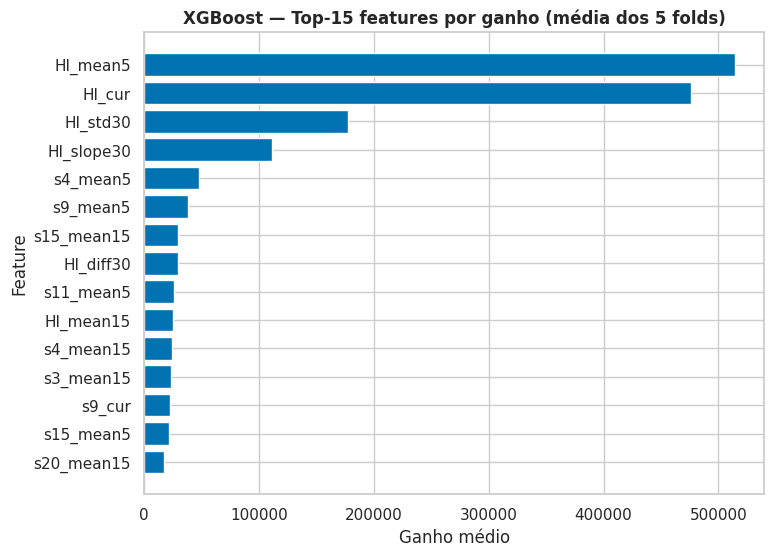

Feature de maior ganho: **HI_mean5**; 6 das 15 principais derivam do HI e 11 são médias/inclinações de janela — o modelo explora sobretudo a tendência suavizada.

In [ ]:
XGB_FINAL = xgb_cv(XGB_BEST, keep=True)
for k, mdl in enumerate(XGB_FINAL["models"]):
    mdl.save_model(MODEL_DIR / f"B1_xgb_fold{k}.json")
register("B1-XGBoost", "B", XGB_FINAL["oof"], XGB_FINAL["test_mean"], note="ensemble 5 folds")
display(leaderboard(["B1-XGBoost"]))

imp = pd.DataFrame([m.get_booster().get_score(importance_type="gain") for m in XGB_FINAL["models"]]).fillna(0.0).mean().sort_values(ascending=False)
top15 = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15.index, top15.values, color=PAL[0])
ax.set(title="XGBoost — Top-15 features por ganho (média dos 5 folds)", xlabel="Ganho médio", ylabel="Feature")
savefig(fig, "B1_xgb_top15_gain")
md_out(f"Feature de maior ganho: **{imp.index[0]}**; {sum(f.startswith('HI') for f in imp.head(15).index)} das 15 principais derivam do HI e "
       f"{sum(('mean' in f) or ('slope' in f) for f in imp.head(15).index)} são médias/inclinações de janela — o modelo explora sobretudo a tendência suavizada.")

## B2. LSTM empilhada (PyTorch + AMP)
Janelas `(N, 30, 14)` dos sensores padronizados pelo scaler do fold; alvo $\text{RUL}_{clip}/125$. LSTM 128 → 64 (dropout 0,25) + `LayerNorm` + MLP (`Linear → GELU → Dropout → Linear(1)`); `AdamW`, `ReduceLROnPlateau`, early stopping (paciência 15, máx. 100 épocas) na validação interna, clipping de gradiente 1,0.

In [ ]:
class LSTMRegressor(nn.Module):
    def __init__(self, n_feat, h1=128, h2=64, drop=0.25, bidirectional=LSTM_BIDIRECTIONAL):
        super().__init__()
        d = 2 if bidirectional else 1
        self.lstm1 = nn.LSTM(n_feat, h1, batch_first=True, bidirectional=bidirectional)
        self.drop = nn.Dropout(drop)
        self.lstm2 = nn.LSTM(h1 * d, h2, batch_first=True, bidirectional=bidirectional)
        self.norm = nn.LayerNorm(h2 * d)
        self.head = nn.Sequential(nn.Linear(h2 * d, 64), nn.GELU(), nn.Dropout(drop), nn.Linear(64, 1))
    def forward(self, x):
        x, _ = self.lstm1(x)
        x, _ = self.lstm2(self.drop(x))
        return self.head(self.norm(x[:, -1])).squeeze(-1)

class CNN1DRegressor(nn.Module):
    def __init__(self, n_feat, channels=(64, 64, 64), kernels=(5, 3, 3), drop=0.2):
        super().__init__()
        layers, c_in = [], n_feat
        for c, k in zip(channels, kernels):
            layers += [nn.Conv1d(c_in, c, k, padding=k // 2), nn.BatchNorm1d(c), nn.GELU(), nn.Dropout(drop)]
            c_in = c
        self.conv = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(c_in, 64), nn.GELU(), nn.Dropout(drop), nn.Linear(64, 1))
    def forward(self, x):                      # x: (B, T, F) → Conv1d espera (B, F, T)
        return self.head(self.pool(self.conv(x.transpose(1, 2)))).squeeze(-1)

def make_base_loss():
    return nn.SmoothL1Loss(beta=NN_SMOOTHL1_BETA_CYCLES / RUL_CLIP) if NN_LOSS == "smoothl1" else nn.MSELoss()

In [ ]:
@torch.no_grad()
def predict_nn(model, W, bs=4096):
    model.eval(); outs = []
    for i in range(0, len(W), bs):
        xb = torch.from_numpy(W[i:i + bs]).to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            outs.append(model(xb).float().cpu().numpy())
    return np.concatenate(outs) * RUL_CLIP

def fit_nn(model, Wfit, yfit, Win, yin, loss_fn):
    gen = torch.Generator().manual_seed(SEED)
    dl = DataLoader(TensorDataset(torch.from_numpy(Wfit), torch.from_numpy(yfit)), batch_size=NN_BATCH, shuffle=True,
                    pin_memory=PIN, num_workers=NN_WORKERS, persistent_workers=NN_WORKERS > 0, generator=gen)
    yin_t = torch.from_numpy(yin).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=NN_LR, weight_decay=NN_WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5)
    grad_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(1, NN_MAX_EPOCHS + 1):
        model.train(); tot, n = 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(xb)
            loss = loss_fn(out.float(), yb)              # perda sempre em float32
            grad_scaler.scale(loss).backward()
            grad_scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            grad_scaler.step(opt); grad_scaler.update()
            tot += loss.item() * len(xb); n += len(xb)
        p_in = predict_nn(model, Win) / RUL_CLIP
        vloss = float(loss_fn(torch.from_numpy(p_in.astype(np.float32)).to(DEVICE), yin_t).item())
        sched.step(vloss)
        hist.append({"epoch": ep, "train_loss": tot / n, "val_loss": vloss, "val_RMSE_ciclos": rmse(yin * RUL_CLIP, p_in * RUL_CLIP),
                     "lr": opt.param_groups[0]["lr"]})
        if vloss < best - 1e-7:
            best, wait = vloss, 0
            best_state = {kk: v.detach().cpu().clone() for kk, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= NN_PATIENCE:
                break
    if best_state is None:
        warnings.warn("Perda de validação nunca finita: mantendo os pesos da última época.")
    else:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

NN_RESULTS = {}
def run_nn_cv(name, build_fn, loss_fn):
    y_s = (train["RUL_clip"].values / RUL_CLIP).astype(np.float32)
    oof, test_folds, hists = np.zeros(len(VAL_CUTS)), [], []
    for k, F in enumerate(FOLDS):
        set_seed(SEED + k)
        sc = fold_scaler(k)
        Xtr = sc.transform(train[SENSORS]).astype(np.float32)
        Xte = sc.transform(test[SENSORS]).astype(np.float32)
        r_fit = np.where(train.unit_id.isin(F["fit"]).values & ELIG)[0]
        r_in = np.where(train.unit_id.isin(F["inner"]).values & ELIG)[0]
        t0 = time.time()
        model, h = fit_nn(build_fn().to(DEVICE), make_windows(Xtr, r_fit), y_s[r_fit], make_windows(Xtr, r_in), y_s[r_in], loss_fn)
        h["fold"] = k; hists.append(h)
        torch.save(model.state_dict(), MODEL_DIR / f"{name}_fold{k}.pt")
        joblib.dump(sc, MODEL_DIR / f"{name}_scaler_fold{k}.joblib")
        idx = (VAL_CUTS.fold == k).values
        oof[idx] = predict_nn(model, make_windows(Xtr, VAL_CUTS.row.values[idx]))
        test_folds.append(predict_nn(model, make_windows(Xte, TEST_LAST.row.values)))
        print(f"{name} fold {k}: {len(h)} épocas | RMSE val. interna {h.val_RMSE_ciclos.min():.2f} | "
              f"RMSE OOF fold {rmse(Y_OOF[idx], np.maximum(oof[idx], 0)):.2f} | {time.time() - t0:.0f}s")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    NN_RESULTS[name] = {"hist": pd.concat(hists, ignore_index=True), "test_folds": np.array(test_folds)}
    return oof, np.mean(test_folds, axis=0)

def plot_loss_curves(name):
    h = NN_RESULTS[name]["hist"]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for k, col in zip(range(N_FOLDS), PAL):
        hk = h[h.fold == k]
        ax.plot(hk.epoch, hk.train_loss, color=col, lw=1.4, label=f"fold {k} treino")
        ax.plot(hk.epoch, hk.val_loss, color=col, lw=1.4, ls="--", label=f"fold {k} val. interna")
    ax.set_yscale("log")
    ax.set(title=f"{name}: curvas de perda (treino × validação interna)", xlabel="Época", ylabel="Perda (escala log)")
    ax.legend(fontsize=7, ncol=2); savefig(fig, f"{name}_curvas_loss")

B2-LSTM fold 0: 26 épocas | RMSE val. interna 13.68 | RMSE OOF fold 36.59 | 21s
B2-LSTM fold 1: 26 épocas | RMSE val. interna 13.38 | RMSE OOF fold 34.05 | 13s
B2-LSTM fold 2: 22 épocas | RMSE val. interna 14.34 | RMSE OOF fold 36.07 | 11s
B2-LSTM fold 3: 40 épocas | RMSE val. interna 12.57 | RMSE OOF fold 33.48 | 19s
B2-LSTM fold 4: 38 épocas | RMSE val. interna 14.36 | RMSE OOF fold 33.90 | 18s


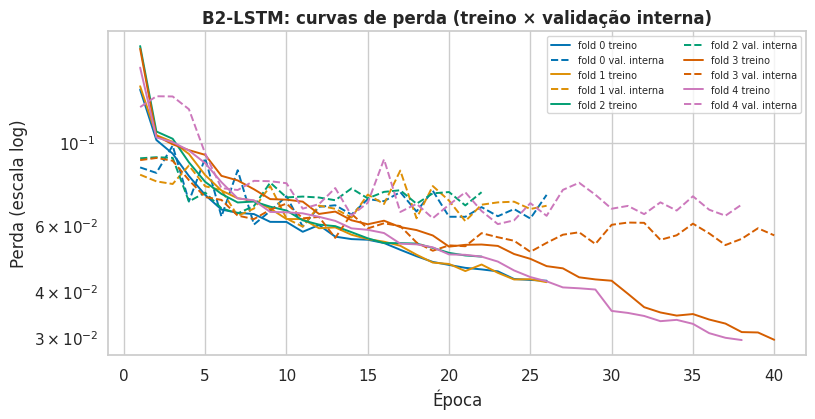

,Trilha,RMSE OOF,MAE OOF,NASA médio OOF,RMSE teste,MAE teste,NASA total teste,% perigosas teste
Modelo,,,,,,,,
B2-LSTM,B,34.8395,21.2624,"5,682.2689",14.8861,11.1742,417.3159,68.0000


In [ ]:
N_FEAT = len(SENSORS)
oof, tp = run_nn_cv("B2-LSTM", lambda: LSTMRegressor(N_FEAT), make_base_loss())
register("B2-LSTM", "B", oof, tp, note=f"{'BiLSTM' if LSTM_BIDIRECTIONAL else 'LSTM'} 128→64, ensemble 5 folds")
plot_loss_curves("B2-LSTM")
display(leaderboard(["B2-LSTM"]))

## B3. 1D-CNN temporal (PyTorch + AMP)
Três blocos `Conv1d` (kernels 5, 3, 3) + `BatchNorm1d` + `GELU` + `Dropout`, `AdaptiveAvgPool1d` e MLP final, mesmas janelas, folds, scaler e otimização da B2.

B3-CNN1D fold 0: 45 épocas | RMSE val. interna 18.20 | RMSE OOF fold 39.35 | 20s
B3-CNN1D fold 1: 26 épocas | RMSE val. interna 15.69 | RMSE OOF fold 39.15 | 10s
B3-CNN1D fold 2: 49 épocas | RMSE val. interna 18.67 | RMSE OOF fold 39.67 | 21s
B3-CNN1D fold 3: 19 épocas | RMSE val. interna 18.02 | RMSE OOF fold 40.15 | 7s
B3-CNN1D fold 4: 22 épocas | RMSE val. interna 20.26 | RMSE OOF fold 36.16 | 11s


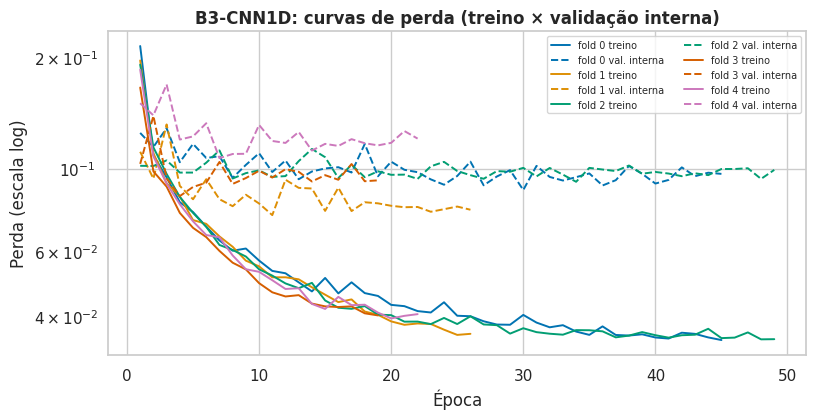

,Trilha,RMSE OOF,MAE OOF,NASA médio OOF,RMSE teste,MAE teste,NASA total teste,% perigosas teste
Modelo,,,,,,,,
B2-LSTM,B,34.8395,21.2624,"5,682.2689",14.8861,11.1742,417.3159,68.0000
B3-CNN1D,B,38.9209,26.1676,"10,526.4678",19.3498,14.6196,"1,113.3689",59.0000


In [ ]:
oof, tp = run_nn_cv("B3-CNN1D", lambda: CNN1DRegressor(N_FEAT), make_base_loss())
register("B3-CNN1D", "B", oof, tp, note="1D-CNN, ensemble 5 folds")
plot_loss_curves("B3-CNN1D")
display(leaderboard(["B2-LSTM", "B3-CNN1D"]))

## B4. Rede sensível ao risco (perda assimétrica)
A melhor arquitetura **pelo RMSE OOF** (B2 vs. B3) é re-treinada com
$$\mathcal L=\lambda\,\overline{s(\text{clamp}(d,\pm50))}+(1-\lambda)\,\overline{\text{Huber}_{10}(d)}/10,\quad d=(\hat y-y)\cdot125,$$
onde $s$ é a NASA Score (penaliza mais a superestimação). O `clamp` limita o termo exponencial a $e^{5}$ (sem explosão de gradiente); o termo Huber mantém gradiente fora do clamp. $\lambda$=`ASYM_LAMBDA`.

B4-RiskAware-LSTM fold 0: 24 épocas | RMSE val. interna 13.47 | RMSE OOF fold 37.65 | 14s
B4-RiskAware-LSTM fold 1: 24 épocas | RMSE val. interna 13.65 | RMSE OOF fold 36.00 | 14s
B4-RiskAware-LSTM fold 2: 22 épocas | RMSE val. interna 14.10 | RMSE OOF fold 40.05 | 13s
B4-RiskAware-LSTM fold 3: 35 épocas | RMSE val. interna 12.65 | RMSE OOF fold 34.42 | 44s
B4-RiskAware-LSTM fold 4: 27 épocas | RMSE val. interna 13.82 | RMSE OOF fold 34.23 | 23s


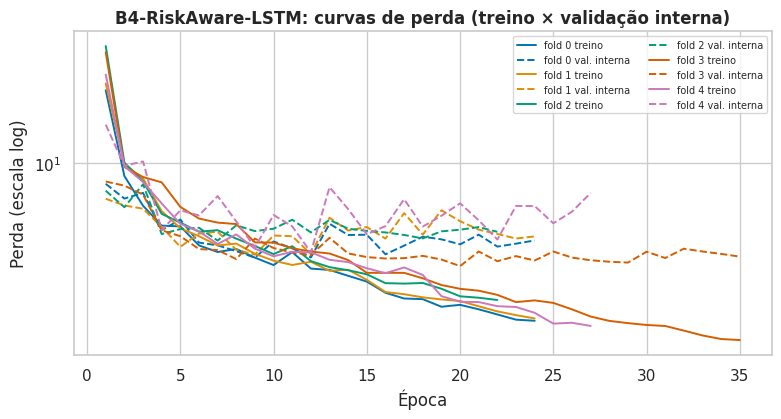

,Trilha,RMSE OOF,MAE OOF,NASA médio OOF,RMSE teste,MAE teste,NASA total teste,% perigosas teste
Modelo,,,,,,,,
B2-LSTM,B,34.8395,21.2624,"5,682.2689",14.8861,11.1742,417.3159,68.0000
B4-RiskAware-LSTM,B,36.5356,22.1818,"9,982.5614",14.8779,10.7386,310.0350,53.0000


Arquitetura base escolhida no OOF: **B2-LSTM**. Com a perda assimétrica, a NASA média OOF foi de 5682.27 para **9982.56** e a fração de predições perigosas no teste de 68% para **53%** (RMSE OOF 34.84 → 36.54).

In [ ]:
class AsymmetricNASALoss(nn.Module):
    def __init__(self, lam=ASYM_LAMBDA, d_clamp=ASYM_DCLAMP, delta=10.0, scale=RUL_CLIP):
        super().__init__()
        self.lam, self.d_clamp, self.delta, self.scale = lam, d_clamp, delta, scale
    def forward(self, pred, target):
        d = (pred - target) * self.scale
        dc = d.clamp(-self.d_clamp, self.d_clamp)
        nasa = torch.where(dc < 0, torch.exp(-dc / 13.0) - 1.0, torch.exp(dc / 10.0) - 1.0)
        hub = nn.functional.huber_loss(d, torch.zeros_like(d), delta=self.delta, reduction="none") / self.delta
        return (self.lam * nasa + (1 - self.lam) * hub).mean()

_l = AsymmetricNASALoss()
_z = torch.zeros(1)
assert _l(_z + 10 / RUL_CLIP, _z) > _l(_z - 10 / RUL_CLIP, _z), "a perda deve penalizar mais a superestimação"

NN_BUILDERS = {"B2-LSTM": lambda: LSTMRegressor(N_FEAT), "B3-CNN1D": lambda: CNN1DRegressor(N_FEAT)}
BEST_ARCH = min(NN_BUILDERS, key=lambda n: rmse(Y_OOF, REGISTRY[n]["oof"]))
B4_NAME = f"B4-RiskAware-{BEST_ARCH.split('-')[1]}"
oof, tp = run_nn_cv(B4_NAME, NN_BUILDERS[BEST_ARCH], AsymmetricNASALoss())
register(B4_NAME, "B", oof, tp, note=f"{BEST_ARCH} + perda assimétrica NASA (λ={ASYM_LAMBDA})")
plot_loss_curves(B4_NAME)
lb4 = leaderboard([BEST_ARCH, B4_NAME]); display(lb4)
md_out(f"Arquitetura base escolhida no OOF: **{BEST_ARCH}**. Com a perda assimétrica, a NASA média OOF foi de "
       f"{lb4.loc[BEST_ARCH, 'NASA médio OOF']:.2f} para **{lb4.loc[B4_NAME, 'NASA médio OOF']:.2f}** e a fração de predições perigosas no teste "
       f"de {lb4.loc[BEST_ARCH, '% perigosas teste']:.0f}% para **{lb4.loc[B4_NAME, '% perigosas teste']:.0f}%** "
       f"(RMSE OOF {lb4.loc[BEST_ARCH, 'RMSE OOF']:.2f} → {lb4.loc[B4_NAME, 'RMSE OOF']:.2f}).")

## B5. Sensibilidade do teto de RUL (XGBoost GPU, mesmos folds e hiperparâmetros)
Teto ∈ {115, 125, 135} só no alvo de treino; avaliação sempre contra o RUL real. **A escolha é julgada pelo OOF**; o teste é mostrado apenas como confirmação. (Hiperparâmetros foram ajustados com teto 125 — leve vantagem estrutural para 125, declarada.)

In [ ]:
clip_rows = []
for clip in CLIP_GRID:
    r = xgb_cv(XGB_BEST, clip=clip, keep=True)
    o, t = regression_metrics(Y_OOF, np.maximum(r["oof"], 0)), regression_metrics(Y_TEST, np.maximum(r["test_mean"], 0))
    t_le, t_gt = regression_metrics(Y_TEST[M_LE], np.maximum(r["test_mean"], 0)[M_LE]), regression_metrics(Y_TEST[M_GT], np.maximum(r["test_mean"], 0)[M_GT])
    clip_rows.append({"RUL_CLIP": clip, "RMSE OOF": o["RMSE"], "NASA médio OOF": o["NASA_medio"], "RMSE teste": t["RMSE"],
                      "NASA total teste": t["NASA_total"], f"RMSE teste RUL≤{RUL_CLIP}": t_le["RMSE"], f"RMSE teste RUL>{RUL_CLIP}": t_gt["RMSE"]})
CLIP_ABLATION = pd.DataFrame(clip_rows).set_index("RUL_CLIP")
display(CLIP_ABLATION); save_table(CLIP_ABLATION, "B5_ablacao_rul_clip")
best_clip = int(CLIP_ABLATION["RMSE OOF"].idxmin())
gap = CLIP_ABLATION.loc[RUL_CLIP, "RMSE OOF"] - CLIP_ABLATION["RMSE OOF"].min()
md_out(f"Menor RMSE OOF com teto **{best_clip}**. O teto contratado ({RUL_CLIP}) fica a **{gap:.2f} ciclos** do melhor no OOF → "
       + ("escolha robusta (diferença < 1 ciclo)." if gap < 1 else "diferença não desprezível: revisar o teto antes de publicar."))

,RMSE OOF,NASA médio OOF,RMSE teste,NASA total teste,RMSE teste RUL≤125,RMSE teste RUL>125
RUL_CLIP,,,,,,
115,36.6853,"12,822.7030",14.1033,288.3318,12.1128,24.9221
125,34.1077,"9,015.1374",14.1097,334.8606,13.4617,18.5376
135,32.3088,"7,103.4270",15.0500,433.7069,15.2071,13.7131


Menor RMSE OOF com teto **135**. O teto contratado (125) fica a **1.80 ciclos** do melhor no OOF → diferença não desprezível: revisar o teto antes de publicar.

### Checkpoint consolidado — predições no teste (100 linhas) e OOF

In [ ]:
PRED_TEST = TEST_LAST[["unit_id", "cycle"]].rename(columns={"cycle": "ultimo_ciclo"}).assign(RUL_real=Y_TEST)
for name, r in REGISTRY.items():
    PRED_TEST[f"RUL_hat_{name}"] = r["test"]
assert len(PRED_TEST) == 100 and PRED_TEST.unit_id.is_unique
PRED_TEST.to_csv(PRED_DIR / "predicoes_teste_FD001.csv", index=False)
PRED_OOF = VAL_CUTS[["unit_id", "cycle", "fold", "RUL"]].copy()
for name, r in REGISTRY.items():
    PRED_OOF[f"RUL_hat_{name}"] = r["oof"]
PRED_OOF.to_csv(PRED_DIR / "predicoes_oof_snapshots.csv", index=False)
display(PRED_TEST.head())
print("Modelos registrados:", list(REGISTRY))

,unit_id,ultimo_ciclo,RUL_real,RUL_hat_A1-Weibull2P,RUL_hat_A1-Lognormal,RUL_hat_A1-Weibull3P,RUL_hat_A2-Wiener-pop,RUL_hat_A2-Wiener-bayes,RUL_hat_B1-XGBoost,RUL_hat_B2-LSTM,RUL_hat_B3-CNN1D,RUL_hat_B4-RiskAware-LSTM
0,1,31,112.0000,174.1374,175.1783,175.3156,135.3366,214.1832,110.5002,120.2515,118.7500,115.1489
1,2,49,98.0000,156.3079,157.1783,157.3156,109.9441,161.5019,122.0067,123.8647,114.5996,120.7520
2,3,126,69.0000,87.3995,81.3825,80.3298,77.2150,100.1714,51.3214,43.8232,54.4922,42.0715
3,4,106,82.0000,103.4900,100.3081,100.3156,90.6017,131.4194,88.9843,80.5176,95.0806,73.6328
4,5,98,91.0000,110.3599,108.2164,108.3156,95.3454,132.8009,107.6302,110.6689,106.5308,102.7466


Modelos registrados: ['A1-Weibull2P', 'A1-Lognormal', 'A1-Weibull3P', 'A2-Wiener-pop', 'A2-Wiener-bayes', 'B1-XGBoost', 'B2-LSTM', 'B3-CNN1D', 'B4-RiskAware-LSTM']


<a id="s5"></a>
# Seção 5 — Análise comparativa e testes estatísticos

### 5.1 Tabela comparativa principal (teste, N=100) + subgrupos (RUL ≤ 125 / > 125)
Os representantes usados na inferência são escolhidos **no OOF**: melhor Trilha B, melhor A1 populacional e melhor variante Wiener.

In [ ]:
rows = []
for name, r in REGISTRY.items():
    t = regression_metrics(Y_TEST, r["test"]); le = regression_metrics(Y_TEST[M_LE], r["test"][M_LE]); gt = regression_metrics(Y_TEST[M_GT], r["test"][M_GT])
    rows.append({"Modelo": name, "Trilha": r["track"], "MAE": t["MAE"], "RMSE": t["RMSE"], "R2": t["R2"], "NASA total": t["NASA_total"],
                 "NASA médio": t["NASA_medio"], "% perigosas": t["pct_perigosas"],
                 f"RMSE (≤{RUL_CLIP}, n={M_LE.sum()})": le["RMSE"], f"NASA médio (≤{RUL_CLIP})": le["NASA_medio"],
                 f"RMSE (>{RUL_CLIP}, n={M_GT.sum()})": gt["RMSE"], f"NASA médio (>{RUL_CLIP})": gt["NASA_medio"],
                 "RMSE OOF": regression_metrics(Y_OOF, r["oof"])["RMSE"]})
MAIN_TABLE = pd.DataFrame(rows).set_index("Modelo").sort_values("RMSE OOF")
display(MAIN_TABLE); save_table(MAIN_TABLE, "tabela_comparativa_principal")

oof_rmse = MAIN_TABLE["RMSE OOF"]
BEST_B = oof_rmse[MAIN_TABLE.Trilha == "B"].idxmin()
BEST_A1 = oof_rmse[[n for n in MAIN_TABLE.index if n.startswith("A1-")]].idxmin()
BEST_WIENER = oof_rmse[[n for n in MAIN_TABLE.index if n.startswith("A2-")]].idxmin()
A_REPS = list(dict.fromkeys(["A1-Lognormal", "A1-Weibull3P", BEST_WIENER]))
MAIN_MODELS = list(dict.fromkeys([BEST_A1, BEST_WIENER, "B1-XGBoost", BEST_B, B4_NAME]))
md_out(f"Melhor Trilha B (OOF): **{BEST_B}** — RMSE teste {MAIN_TABLE.loc[BEST_B, 'RMSE']:.2f}, NASA total {MAIN_TABLE.loc[BEST_B, 'NASA total']:.1f}. "
       f"Melhor A1: **{BEST_A1}** (RMSE teste {MAIN_TABLE.loc[BEST_A1, 'RMSE']:.2f}); melhor Wiener: **{BEST_WIENER}** (RMSE teste {MAIN_TABLE.loc[BEST_WIENER, 'RMSE']:.2f}). "
       f"Nos {M_GT.sum()} motores com RUL > {RUL_CLIP}, o RMSE de {BEST_B} é {MAIN_TABLE.loc[BEST_B, f'RMSE (>{RUL_CLIP}, n={M_GT.sum()})']:.1f} "
       f"contra {MAIN_TABLE.loc[BEST_B, f'RMSE (≤{RUL_CLIP}, n={M_LE.sum()})']:.1f} nos demais (efeito esperado do teto: o alvo nunca passa de {RUL_CLIP}).")

,Trilha,MAE,RMSE,R2,NASA total,NASA médio,% perigosas,"RMSE (≤125, n=89)",NASA médio (≤125),"RMSE (>125, n=11)",NASA médio (>125),RMSE OOF
Modelo,,,,,,,,,,,,
B1-XGBoost,B,10.4637,14.1097,0.8847,334.8606,3.3486,58.0000,13.4617,3.3609,18.5376,3.2491,34.1077
B2-LSTM,B,11.1742,14.8861,0.8717,417.3159,4.1732,68.0000,14.3489,4.2781,18.6724,3.3242,34.8395
B4-RiskAware-LSTM,B,10.7386,14.8779,0.8718,310.0350,3.1004,53.0000,12.9212,2.6420,25.7187,6.8086,36.5356
B3-CNN1D,B,14.6196,19.3498,0.7832,"1,113.3689",11.1337,59.0000,18.8183,11.8586,23.2069,5.2686,38.9209
A2-Wiener-pop,A,20.7514,25.8700,0.6124,"3,294.1892",32.9419,75.0000,26.5628,36.5056,19.3732,4.1079,39.6052
A1-Lognormal,A,31.6483,37.1191,0.2021,"8,438.9843",84.3898,66.0000,37.0176,83.2574,37.9306,93.5524,42.0432
A1-Weibull3P,A,31.7256,37.0381,0.2056,"7,986.1167",79.8612,66.0000,36.9731,79.8848,37.5597,79.6703,42.0523
A1-Weibull2P,A,32.3562,37.7995,0.1726,"10,521.4273",105.2143,65.0000,38.1860,111.2443,34.5137,56.4256,43.1564
A2-Wiener-bayes,A,44.5150,51.8792,-0.5586,"1,156,129.0398","11,561.2904",97.0000,52.3043,"12,926.9568",48.3023,511.8076,50.5864


Melhor Trilha B (OOF): **B1-XGBoost** — RMSE teste 14.11, NASA total 334.9. Melhor A1: **A1-Lognormal** (RMSE teste 37.12); melhor Wiener: **A2-Wiener-pop** (RMSE teste 25.87). Nos 11 motores com RUL > 125, o RMSE de B1-XGBoost é 18.5 contra 13.5 nos demais (efeito esperado do teto: o alvo nunca passa de 125).

### 5.2 Gráficos comparativos

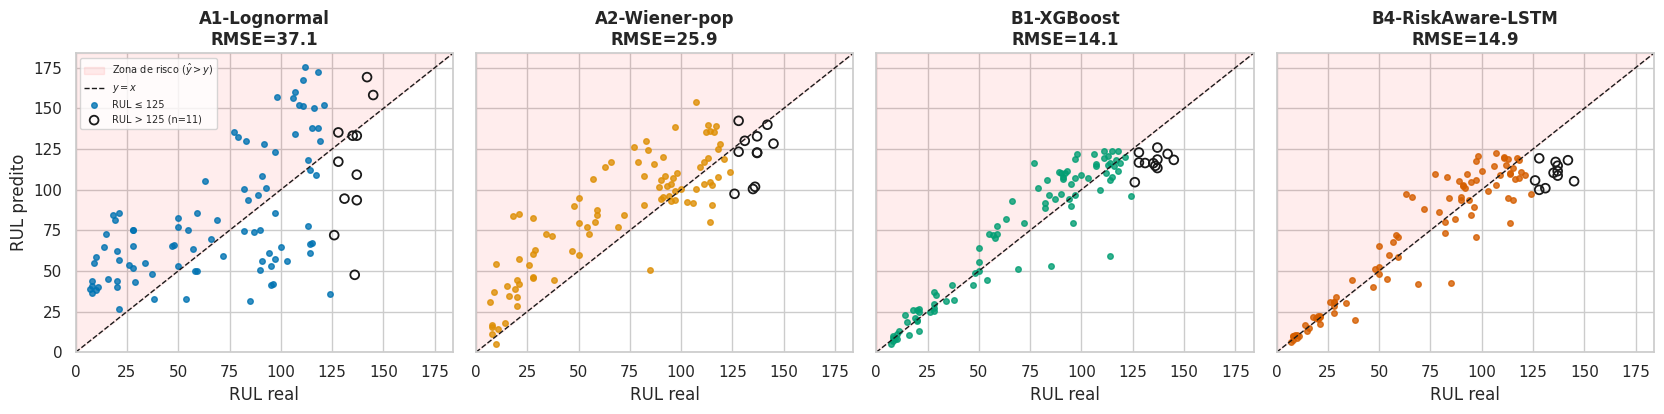

In [ ]:
n_m = len(MAIN_MODELS)
fig, axs = plt.subplots(1, n_m, figsize=(4.2 * n_m, 4.3), sharex=True, sharey=True)
lim = max(Y_TEST.max(), max(REGISTRY[m]["test"].max() for m in MAIN_MODELS)) * 1.05
xx = np.linspace(0, lim, 50)
for ax, m, col in zip(np.atleast_1d(axs), MAIN_MODELS, PAL):
    p = REGISTRY[m]["test"]
    ax.fill_between(xx, xx, lim, color="red", alpha=.07, label="Zona de risco ($\\hat{y}>y$)")
    ax.plot(xx, xx, "k--", lw=1, label="$y=x$")
    ax.scatter(Y_TEST[M_LE], p[M_LE], s=16, color=col, alpha=.8, label=f"RUL ≤ {RUL_CLIP}")
    ax.scatter(Y_TEST[M_GT], p[M_GT], s=40, facecolor="none", edgecolor="k", lw=1.3, label=f"RUL > {RUL_CLIP} (n={M_GT.sum()})")
    ax.set(title=f"{m}\nRMSE={rmse(Y_TEST, p):.1f}", xlabel="RUL real", xlim=(0, lim), ylim=(0, lim))
np.atleast_1d(axs)[0].set_ylabel("RUL predito"); np.atleast_1d(axs)[0].legend(fontsize=7)
fig.tight_layout(); savefig(fig, "C1_dispersao_real_vs_predito")

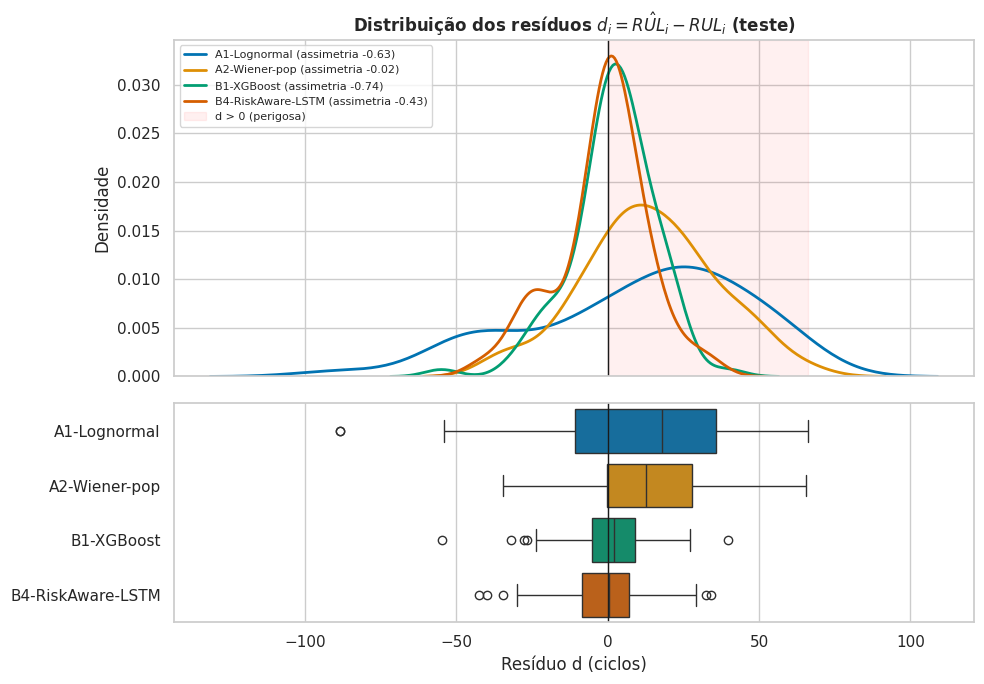

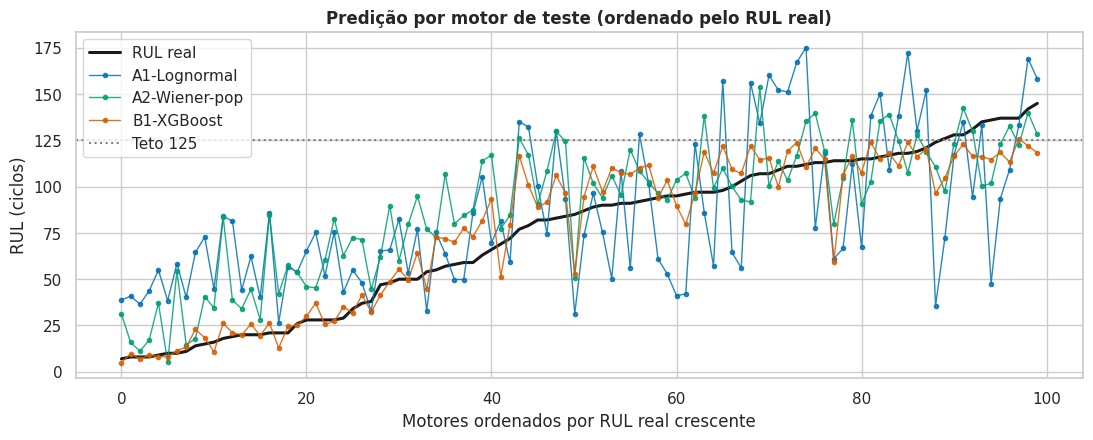

In [ ]:
res_df = pd.DataFrame({m: REGISTRY[m]["test"] - Y_TEST for m in MAIN_MODELS})
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1.3]})
for m, col in zip(MAIN_MODELS, PAL):
    sns.kdeplot(res_df[m], ax=axs[0], color=col, lw=2, label=f"{m} (assimetria {stats.skew(res_df[m]):+.2f})")
axs[0].axvline(0, c="k", lw=1); axs[0].axvspan(0, res_df.values.max(), color="red", alpha=.06, label="d > 0 (perigosa)")
axs[0].set(title="Distribuição dos resíduos $d_i=\\hat{RUL}_i-RUL_i$ (teste)", ylabel="Densidade"); axs[0].legend(fontsize=8)
sns.boxplot(data=res_df.melt(var_name="Modelo", value_name="d"), x="d", y="Modelo", ax=axs[1], palette=PAL[:n_m], hue="Modelo", legend=False)
axs[1].axvline(0, c="k", lw=1); axs[1].set(xlabel="Resíduo d (ciclos)", ylabel="")
fig.tight_layout(); savefig(fig, "C2_residuos_kde_boxplot")

order = np.argsort(Y_TEST)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(np.arange(100), Y_TEST[order], "k-", lw=2.2, label="RUL real")
for m, col in zip(list(dict.fromkeys([BEST_A1, BEST_WIENER, BEST_B])), (PAL[0], PAL[2], PAL[3])):
    ax.plot(np.arange(100), REGISTRY[m]["test"][order], "o-", ms=3, lw=1, color=col, alpha=.85, label=m)
ax.axhline(RUL_CLIP, c="gray", ls=":", label=f"Teto {RUL_CLIP}")
ax.set(title="Predição por motor de teste (ordenado pelo RUL real)", xlabel="Motores ordenados por RUL real crescente", ylabel="RUL (ciclos)")
ax.legend(); savefig(fig, "C3_predicao_por_motor")

### 5.3 Inferência pareada por motor (N=100)
**(a) Premissas:** Shapiro-Wilk e Q-Q das diferenças pareadas $\Delta_{|d|,i}=|d_i^{B}|-|d_i^{A}|$ e $\Delta_{s,i}=s_i^{B}-s_i^{A}$ (B = melhor Trilha B; A = Lognormal, Weibull 3P, melhor Wiener). **(b) Demonstração do teste t ingênuo:** comparação ciclo a ciclo (todas as linhas OOF) × agregada por motor.

,comparação,métrica,média Δ,mediana Δ,Shapiro W,Shapiro p,normal a 5%?
0,B1-XGBoost − A1-Lognormal,|d|,-21.1846,-22.7259,0.9881,0.5184,True
1,B1-XGBoost − A1-Lognormal,s,-81.0412,-13.2762,0.5116,0.0000,False
2,B1-XGBoost − A1-Weibull3P,|d|,-21.2619,-23.4530,0.9861,0.3808,True
3,B1-XGBoost − A1-Weibull3P,s,-76.5126,-13.7866,0.5403,0.0000,False
4,B1-XGBoost − A2-Wiener-pop,|d|,-10.2877,-7.4241,0.9696,0.0208,False
5,B1-XGBoost − A2-Wiener-pop,s,-29.5933,-2.6540,0.3583,0.0000,False


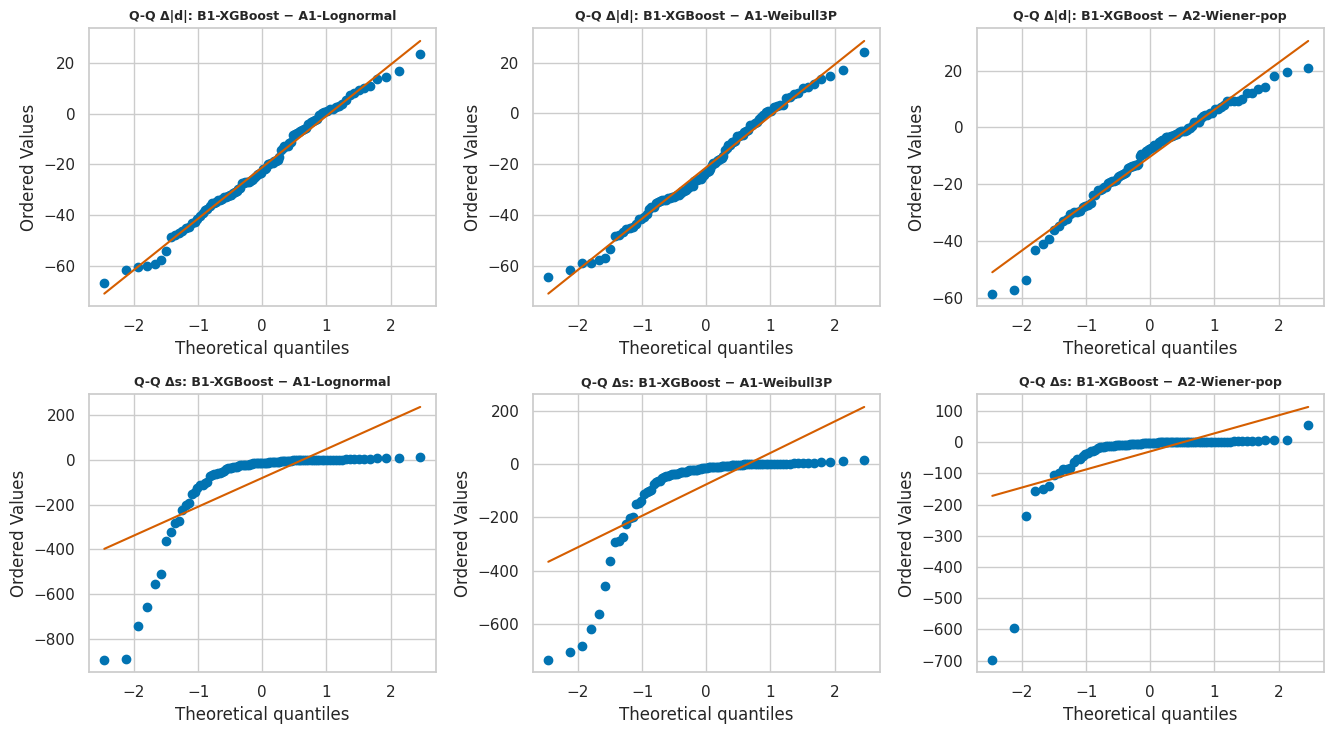

2 de 6 vetores de diferença são compatíveis com normalidade (Shapiro a 5%). Como há rejeições, testes paramétricos pareados não são confiáveis aqui → usam-se Wilcoxon, bootstrap e permutação.

In [ ]:
eB = REGISTRY[BEST_B]["test"] - Y_TEST
DIFFS, sw_rows = {}, []
for a in A_REPS:
    eA = REGISTRY[a]["test"] - Y_TEST
    DIFFS[(a, "|d|")] = np.abs(eB) - np.abs(eA)
    DIFFS[(a, "s")] = nasa_terms(eB) - nasa_terms(eA)
for (a, met), dlt in DIFFS.items():
    w_, p_ = stats.shapiro(dlt)
    sw_rows.append({"comparação": f"{BEST_B} − {a}", "métrica": met, "média Δ": dlt.mean(), "mediana Δ": np.median(dlt),
                    "Shapiro W": w_, "Shapiro p": p_, "normal a 5%?": p_ >= 0.05})
SHAPIRO = pd.DataFrame(sw_rows); display(SHAPIRO)

fig, axs = plt.subplots(2, len(A_REPS), figsize=(4.5 * len(A_REPS), 7.5))
for j, a in enumerate(A_REPS):
    for i, met in enumerate(("|d|", "s")):
        stats.probplot(DIFFS[(a, met)], dist="norm", plot=axs[i, j])
        axs[i, j].set_title(f"Q-Q Δ{met}: {BEST_B} − {a}", fontsize=9)
fig.tight_layout(); savefig(fig, "C4_QQ_diferencas_pareadas")
n_norm = int(SHAPIRO["normal a 5%?"].sum())
md_out(f"{n_norm} de {len(SHAPIRO)} vetores de diferença são compatíveis com normalidade (Shapiro a 5%). "
       + ("Como há rejeições, testes paramétricos pareados não são confiáveis aqui → usam-se Wilcoxon, bootstrap e permutação." if n_norm < len(SHAPIRO)
          else "Mesmo assim, por robustez, a inferência principal usa Wilcoxon, bootstrap e permutação."))

In [ ]:
# Demonstração: XGBoost × Lognormal-MRL em TODAS as linhas OOF (ciclo ≥ seq_len), ciclo a ciclo vs. por motor
mask_rows = ELIG & ~np.isnan(XGB_FINAL["oof_rows"])
logn_rows = np.full(len(train), np.nan)
for k, F in enumerate(FOLDS):
    dist, prm = fit_lifetime_models(Tf_unit.loc[F["train"]].values)["Lognormal"]
    mk = mask_rows & (train.fold == k).values
    logn_rows[mk] = mrl_vec(dist, prm, train.cycle.values[mk])
diff_rows = np.abs(np.maximum(XGB_FINAL["oof_rows"][mask_rows], 0) - train.RUL.values[mask_rows]) - np.abs(logn_rows[mask_rows] - train.RUL.values[mask_rows])
units_rows = train.unit_id.values[mask_rows]
per_unit = pd.Series(diff_rows).groupby(units_rows).mean()
lag1 = np.nanmean([acf(g.values, nlags=1, fft=True)[1] for _, g in pd.Series(diff_rows).groupby(units_rows) if len(g) > 5])
t_naive, t_unit = stats.ttest_1samp(diff_rows, 0.0), stats.ttest_1samp(per_unit.values, 0.0)
NAIVE_T = pd.DataFrame({"N usado": [len(diff_rows), len(per_unit)], "t": [t_naive.statistic, t_unit.statistic], "p": [t_naive.pvalue, t_unit.pvalue]},
                       index=["ingênuo (linha a linha)", "correto (1 valor por motor)"])
display(NAIVE_T)
md_out(f"A diferença de erro absoluto ciclo a ciclo tem autocorrelação lag-1 média de **{lag1:.2f}** dentro do motor. O teste t ingênuo usa "
       f"N={len(diff_rows):,} linhas como se fossem independentes e produz |t| = {abs(t_naive.statistic):.1f}, contra |t| = {abs(t_unit.statistic):.1f} "
       f"com a unidade correta (N={len(per_unit)} motores): inflação de **{abs(t_naive.statistic) / max(abs(t_unit.statistic), 1e-9):.1f}×** na estatística.")

/tmp/ipykernel_947/58844046.py:7: UserWarning: Weibull 3P: loc=133.96 fora de (0, min T_f=128); reajuste com chute inicial.
  warnings.warn(f"Weibull 3P: loc={prm[1]:.2f} fora de (0, min T_f={T.min():.0f}); reajuste com chute inicial.")
/tmp/ipykernel_947/58844046.py:7: UserWarning: Weibull 3P: loc=145.66 fora de (0, min T_f=128); reajuste com chute inicial.
  warnings.warn(f"Weibull 3P: loc={prm[1]:.2f} fora de (0, min T_f={T.min():.0f}); reajuste com chute inicial.")
/tmp/ipykernel_947/58844046.py:7: UserWarning: Weibull 3P: loc=145.66 fora de (0, min T_f=128); reajuste com chute inicial.
  warnings.warn(f"Weibull 3P: loc={prm[1]:.2f} fora de (0, min T_f={T.min():.0f}); reajuste com chute inicial.")


,N usado,t,p
ingênuo (linha a linha),17731,-54.0222,0.0000
correto (1 valor por motor),100,-7.0765,0.0000


A diferença de erro absoluto ciclo a ciclo tem autocorrelação lag-1 média de **0.95** dentro do motor. O teste t ingênuo usa N=17,731 linhas como se fossem independentes e produz |t| = 54.0, contra |t| = 7.1 com a unidade correta (N=100 motores): inflação de **7.6×** na estatística.

### 5.4 Wilcoxon pareado com correção de Holm-Bonferroni (6 comparações: 3 representantes A × {|d|, s})

In [ ]:
def holm(pvals):
    p = np.asarray(pvals, float); m = len(p); adj = np.empty(m); running = 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (m - rank) * p[i])); adj[i] = running
    return adj

wil_rows = []
for (a, met), dlt in DIFFS.items():
    w = stats.wilcoxon(dlt)
    wil_rows.append({"comparação": f"{BEST_B} − {a}", "métrica": met, "mediana Δ": np.median(dlt), "W": w.statistic, "p": w.pvalue,
                     "B melhor?": np.median(dlt) < 0})
WILCOXON = pd.DataFrame(wil_rows)
WILCOXON["p Holm"] = holm(WILCOXON["p"])
WILCOXON["signif. 5% (Holm)"] = WILCOXON["p Holm"] < 0.05
display(WILCOXON); save_table(WILCOXON.set_index(["comparação", "métrica"]), "teste_wilcoxon_holm")

,comparação,métrica,mediana Δ,W,p,B melhor?,p Holm,signif. 5% (Holm)
0,B1-XGBoost − A1-Lognormal,|d|,-22.7259,352.0000,0.0000,True,0.0000,True
1,B1-XGBoost − A1-Lognormal,s,-13.2762,365.0000,0.0000,True,0.0000,True
2,B1-XGBoost − A1-Weibull3P,|d|,-23.4530,360.0000,0.0000,True,0.0000,True
3,B1-XGBoost − A1-Weibull3P,s,-13.7866,372.0000,0.0000,True,0.0000,True
4,B1-XGBoost − A2-Wiener-pop,|d|,-7.4241,981.0000,0.0000,True,0.0000,True
5,B1-XGBoost − A2-Wiener-pop,s,-2.6540,974.0000,0.0000,True,0.0000,True


### 5.5 Bootstrap pareado (B=10.000) e teste de permutação pareado (10.000)
Reamostragem de **motores** (pares preservados). IC 95% percentil, básico e BCa para $\Delta$RMSE, $\Delta$MAE e $\Delta$NASA total (B − A; negativo = Trilha B melhor). Permutação: troca aleatória dos rótulos A/B dentro de cada par.

In [ ]:
RNG_KW = "rng" if "rng" in inspect.signature(stats.bootstrap).parameters else "random_state"
PERM_RNG_KW = "rng" if "rng" in inspect.signature(stats.permutation_test).parameters else "random_state"

def d_rmse(eA, eB, axis=-1): return np.sqrt(np.mean(eB ** 2, axis=axis)) - np.sqrt(np.mean(eA ** 2, axis=axis))
def d_mae(eA, eB, axis=-1): return np.mean(np.abs(eB), axis=axis) - np.mean(np.abs(eA), axis=axis)
def d_nasa(eA, eB, axis=-1): return np.sum(nasa_terms(eB), axis=axis) - np.sum(nasa_terms(eA), axis=axis)
DELTA_STATS = {"ΔRMSE": d_rmse, "ΔMAE": d_mae, "ΔNASA": d_nasa}

boot_rows, BOOT_DIST = [], {}
for a in A_REPS:
    eA = REGISTRY[a]["test"] - Y_TEST
    for lbl, f in DELTA_STATS.items():
        cis = {}
        for meth in ("percentile", "basic", "BCa"):
            res = stats.bootstrap((eA, eB), f, paired=True, vectorized=True, n_resamples=N_BOOT, method=meth,
                                  confidence_level=0.95, **{RNG_KW: SEED})
            cis[meth] = res.confidence_interval
            if meth == "percentile":
                dist_b = res.bootstrap_distribution
        perm = stats.permutation_test((eA, eB), f, permutation_type="samples", vectorized=True, n_resamples=N_PERM,
                                      alternative="two-sided", **{PERM_RNG_KW: SEED})
        BOOT_DIST[(a, lbl)] = dist_b
        boot_rows.append({"comparação": f"{BEST_B} − {a}", "estatística": lbl, "observado": f(eA, eB),
                          "IC95 percentil": (cis["percentile"].low, cis["percentile"].high), "IC95 básico": (cis["basic"].low, cis["basic"].high),
                          "IC95 BCa": (cis["BCa"].low, cis["BCa"].high),
                          "p bootstrap": min(1.0, 2 * min(np.mean(dist_b <= 0), np.mean(dist_b >= 0))), "p permutação": perm.pvalue})
BOOT = pd.DataFrame(boot_rows)
display(BOOT)
BOOT_TAB = BOOT.assign(**{c: BOOT[c].map(lambda ci: f"[{ci[0]:.2f}; {ci[1]:.2f}]") for c in ("IC95 percentil", "IC95 básico", "IC95 BCa")})
save_table(BOOT_TAB.set_index(["comparação", "estatística"]), "bootstrap_permutacao")

,comparação,estatística,observado,IC95 percentil,IC95 básico,IC95 BCa,p bootstrap,p permutação
0,B1-XGBoost − A1-Lognormal,ΔRMSE,-23.0094,"(-27.108590106235134, -18.91898587044834)","(-27.099834866669198, -18.910230630882403)","(-27.12074264036014, -18.92781228760465)",0.0000,0.0002
1,B1-XGBoost − A1-Lognormal,ΔMAE,-21.1846,"(-24.996820600584904, -17.34883468718189)","(-25.020403289184724, -17.37241737578171)","(-24.97817736690911, -17.328396399658523)",0.0000,0.0002
2,B1-XGBoost − A1-Lognormal,ΔNASA,"-8,104.1237","(-11900.74791138847, -4912.292512625804)","(-11295.954867629578, -4307.499468866914)","(-12664.002169665591, -5369.437286531765)",0.0000,0.0002
3,B1-XGBoost − A1-Weibull3P,ΔRMSE,-22.9284,"(-26.91926812277801, -18.952427022761142)","(-26.904333118057366, -18.937492018040498)","(-26.88503664446755, -18.923493227223823)",0.0000,0.0002
4,B1-XGBoost − A1-Weibull3P,ΔMAE,-21.2619,"(-25.08194971584583, -17.422368065778517)","(-25.10145980996305, -17.441878159895737)","(-25.063449052963485, -17.411733455996508)",0.0000,0.0002
5,B1-XGBoost − A1-Weibull3P,ΔNASA,"-7,651.2561","(-10984.75123567389, -4795.726307844516)","(-10506.785881240463, -4317.760953411089)","(-11581.700514587039, -5166.996158385056)",0.0000,0.0002
6,B1-XGBoost − A2-Wiener-pop,ΔRMSE,-11.7603,"(-15.608679250695891, -7.942672822682944)","(-15.577855379261631, -7.911848951248684)","(-15.627065781766442, -7.985533591520102)",0.0000,0.0002
7,B1-XGBoost − A2-Wiener-pop,ΔMAE,-10.2877,"(-13.621116217713706, -7.094776721664714)","(-13.480636197391178, -6.954296701342187)","(-13.706869709579124, -7.171502704108154)",0.0000,0.0002
8,B1-XGBoost − A2-Wiener-pop,ΔNASA,"-2,959.3286","(-5062.247280017054, -1376.1606588149239)","(-4542.496571185233, -856.4099499831027)","(-5819.557635750606, -1634.1824586084763)",0.0000,0.0002


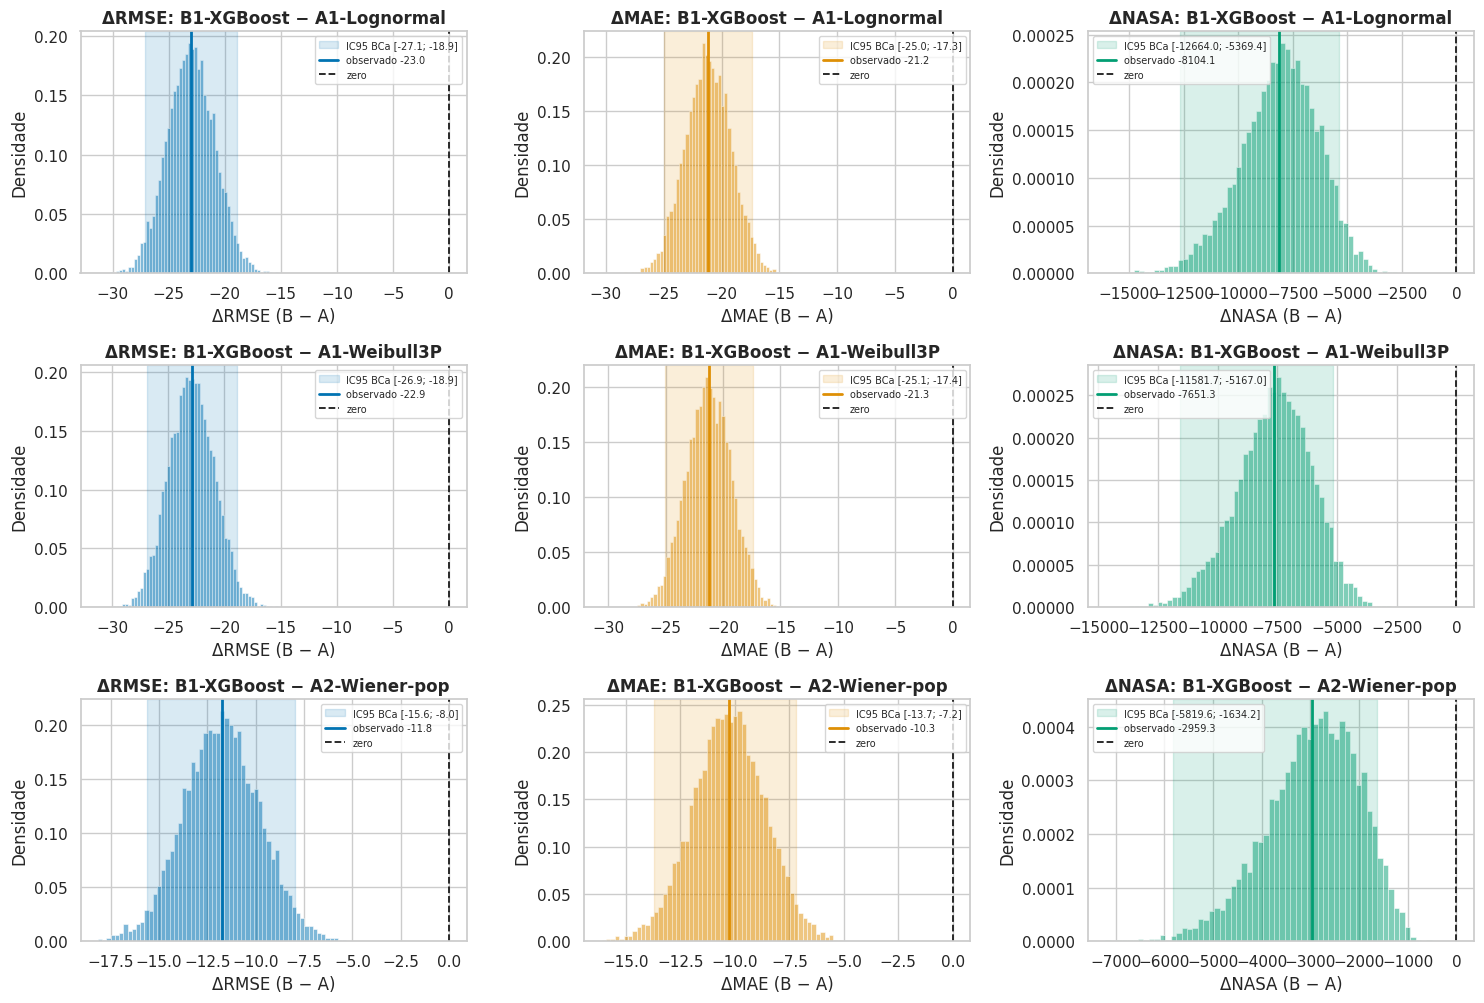

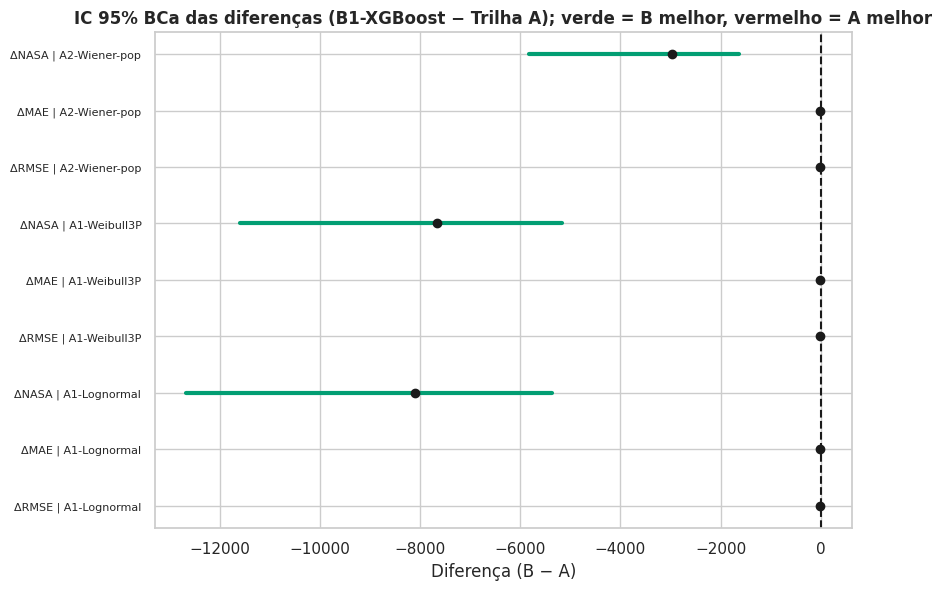

**9 de 9** contrastes têm IC 95% BCa inteiramente abaixo de zero **e** p de permutação < 0,05 (Trilha B significativamente melhor): ΔRMSE vs A1-Lognormal, ΔMAE vs A1-Lognormal, ΔNASA vs A1-Lognormal, ΔRMSE vs A1-Weibull3P, ΔMAE vs A1-Weibull3P, ΔNASA vs A1-Weibull3P, ΔRMSE vs A2-Wiener-pop, ΔMAE vs A2-Wiener-pop, ΔNASA vs A2-Wiener-pop.

In [ ]:
fig, axs = plt.subplots(len(A_REPS), len(DELTA_STATS), figsize=(5 * len(DELTA_STATS), 3.4 * len(A_REPS)), squeeze=False)
for i, a in enumerate(A_REPS):
    for j, lbl in enumerate(DELTA_STATS):
        ax = axs[i, j]; dist_b = BOOT_DIST[(a, lbl)]
        row = BOOT[(BOOT["comparação"] == f"{BEST_B} − {a}") & (BOOT["estatística"] == lbl)].iloc[0]
        sns.histplot(dist_b, bins=60, stat="density", ax=ax, color=PAL[j], alpha=.5)
        lo, hi_ = row["IC95 BCa"]
        ax.axvspan(lo, hi_, color=PAL[j], alpha=.15, label=f"IC95 BCa [{lo:.1f}; {hi_:.1f}]")
        ax.axvline(row["observado"], c=PAL[j], lw=2, label=f"observado {row['observado']:.1f}")
        ax.axvline(0, c="k", ls="--", lw=1.3, label="zero")
        ax.set(title=f"{lbl}: {BEST_B} − {a}", xlabel=lbl + " (B − A)", ylabel="Densidade"); ax.legend(fontsize=7)
fig.tight_layout(); savefig(fig, "C5_bootstrap_distribuicoes")

fig, ax = plt.subplots(figsize=(9, 0.55 * len(BOOT) + 1.5))
labels = [f"{r['estatística']} | {r['comparação'].split(' − ')[1]}" for _, r in BOOT.iterrows()]
for y_, (_, r) in enumerate(BOOT.iterrows()):
    lo, hi_ = r["IC95 BCa"]
    col = PAL[2] if hi_ < 0 else (PAL[3] if lo > 0 else "gray")
    ax.plot([lo, hi_], [y_, y_], color=col, lw=3); ax.plot(r["observado"], y_, "o", color="k")
ax.axvline(0, c="k", ls="--"); ax.set_yticks(range(len(BOOT))); ax.set_yticklabels(labels, fontsize=8)
ax.set(title=f"IC 95% BCa das diferenças ({BEST_B} − Trilha A); verde = B melhor, vermelho = A melhor", xlabel="Diferença (B − A)")
savefig(fig, "C6_forest_IC95")
sig = BOOT[(BOOT["IC95 BCa"].map(lambda c: c[1] < 0)) & (BOOT["p permutação"] < 0.05)]
md_out(f"**{len(sig)} de {len(BOOT)}** contrastes têm IC 95% BCa inteiramente abaixo de zero **e** p de permutação < 0,05 "
       f"(Trilha B significativamente melhor): " + (", ".join(f"{r['estatística']} vs {r['comparação'].split(' − ')[1]}" for _, r in sig.iterrows()) or "nenhum") + ".")

<a id="s6"></a>
# Seção 6 — Política de manutenção preventiva e curvas de custo

**Regra:** retirar o motor quando $\widehat{\text{RUL}}_i\le\tau$, $\tau\in[5,50]$. Avaliação em *snapshot* (um instante por motor): com $\text{RUL}_i\le\tau$ o motor é “crítico” (falharia antes da próxima janela de decisão).

| | $\text{RUL}\le\tau$ | $\text{RUL}>\tau$ |
|---|---|---|
| $\widehat{\text{RUL}}\le\tau$ | preventiva oportuna | preventiva prematura (desperdiça $\text{RUL}_i$ ciclos) |
| $\widehat{\text{RUL}}>\tau$ | **falha corretiva** | operação normal |

Custo (com $C_p=1$): $C = n_{prev} + (C_c/C_p)\,n_{falhas}\;[+\,0{,}01\cdot\text{ciclos descartados}]$. **τ\* de cada modelo é escolhido no OOF** (500 snapshots, custo normalizado para 100 motores) e aplicado no teste. Benchmarks: **Oráculo** ($\widehat{\text{RUL}}=\text{RUL}$) e **preventiva por idade** (retira se $t_i\ge A$, com $A^*$ otimizado nos snapshots do treino). No teste, $\tau\in[20,30]$ concentra 16–25 motores críticos — a faixa com melhor massa amostral.

In [ ]:
def policy_counts(decide, rul, tau):
    decide, rul = np.asarray(decide, bool), np.asarray(rul, float); crit = rul <= tau
    prem = decide & ~crit
    return {"oportunas": int((decide & crit).sum()), "prematuras": int(prem.sum()), "falhas": int((~decide & crit).sum()),
            "normais": int((~decide & ~crit).sum()), "ciclos_desperd_prematuras": float(rul[prem].sum()),
            "media_desperd_prematuras": float(rul[prem].mean()) if prem.any() else 0.0, "ciclos_desperd_total": float(rul[decide].sum())}

def policy_cost(c, ratio, c_cycle=0.0):
    return (c["oportunas"] + c["prematuras"]) + ratio * c["falhas"] + c_cycle * c["ciclos_desperd_total"]

POLICY_MODELS = list(REGISTRY) + ["Oráculo"]
def decisions(name, split, tau):
    if name == "Oráculo":
        return (Y_OOF if split == "oof" else Y_TEST) <= tau
    return REGISTRY[name]["oof" if split == "oof" else "test"] <= tau

OOF_NORM = 100.0 / len(VAL_CUTS)
AGE_GRID = np.arange(int(Tf.min()) - 100, int(Tf.max()) + 1)
cost_rows = []
for cc in (0.0, C_CYCLE):
    for ratio in COST_RATIOS:
        for tau in TAU_GRID:
            for name in POLICY_MODELS:
                for split, rul in (("oof", Y_OOF), ("teste", Y_TEST)):
                    c = policy_counts(decisions(name, split, tau), rul, tau)
                    cost_rows.append({"modelo": name, "c_ciclo": cc, "razao": ratio, "tau": int(tau), "split": split,
                                      "custo": policy_cost(c, ratio, cc) * (OOF_NORM if split == "oof" else 1.0), **c})
            # benchmark por idade: A* escolhido nos snapshots do treino, aplicado no teste
            oof_costs = [policy_cost(policy_counts(VAL_CUTS.cycle.values >= A, Y_OOF, tau), ratio, cc) for A in AGE_GRID]
            A_star = int(AGE_GRID[int(np.argmin(oof_costs))])
            for split, ages, rul, norm_ in (("oof", VAL_CUTS.cycle.values, Y_OOF, OOF_NORM), ("teste", TEST_LAST.cycle.values, Y_TEST, 1.0)):
                c = policy_counts(ages >= A_star, rul, tau)
                cost_rows.append({"modelo": "Idade (sem sensores)", "c_ciclo": cc, "razao": ratio, "tau": int(tau), "split": split,
                                  "custo": policy_cost(c, ratio, cc) * norm_, "A_star": A_star, **c})
COSTS = pd.DataFrame(cost_rows)
print(COSTS.shape, "| modelos:", COSTS.modelo.unique().tolist())

(6072, 14) | modelos: ['A1-Weibull2P', 'A1-Lognormal', 'A1-Weibull3P', 'A2-Wiener-pop', 'A2-Wiener-bayes', 'B1-XGBoost', 'B2-LSTM', 'B3-CNN1D', 'B4-RiskAware-LSTM', 'Oráculo', 'Idade (sem sensores)']


### 6.1 Matriz operacional no teste para τ ∈ {10, 15, 20, 30, 40}

In [ ]:
key = COSTS[(COSTS.split == "teste") & (COSTS.tau.isin(TAUS_KEY)) & (COSTS.c_ciclo == 0) & (COSTS.razao == COST_RATIOS[0])]
OPS_MATRIX = key.pivot_table(index=["modelo", "tau"], values=["oportunas", "prematuras", "falhas", "normais", "ciclos_desperd_prematuras", "media_desperd_prematuras"],
                             aggfunc="first")[["oportunas", "prematuras", "falhas", "normais", "ciclos_desperd_prematuras", "media_desperd_prematuras"]]
display(OPS_MATRIX); save_table(OPS_MATRIX, "politica_matriz_operacional")
crit = {t: int((Y_TEST <= t).sum()) for t in TAUS_KEY}
md_out(f"Motores críticos no teste por τ: {crit}. Para τ ≤ 15 há ≤ {crit[15]} eventos críticos — contagens de falhas nessa faixa têm alta variância.")

oportunas  prematuras  falhas  normais  ciclos_desperd_prematuras  media_desperd_prematuras
modelo               tau                                                                                             
A1-Lognormal         10           0           0       7       93                     0.0000                    0.0000
                     15           0           0      10       90                     0.0000                    0.0000
                     20           0           0      16       84                     0.0000                    0.0000
                     30           1           0      24       75                     0.0000                    0.0000
                     40           5           3      23       69                   263.0000                   87.6667
A1-Weibull2P         10           0           0       7       93                     0.0000                    0.0000
                     15           0           0      10       90                     0.0000                    0.0000
                     20           0           1      16       83                    21.0000                   21.0000
                     30           1           1      24       74                    85.0000                   85.0000
                     40           3           3      25       69                   263.0000                   87.6667
A1-Weibull3P         10           0           0       7       93                     0.0000                    0.0000
                     15           0           0      10       90                     0.0000                    0.0000
                     20           0           0      16       84                     0.0000                    0.0000
                     30           1           0      24       75                     0.0000                    0.0000
                     40           3           3      25       69                   263.0000                   87.6667
A2-Wiener-bayes      10           1           0       6       93                     0.0000                    0.0000
                     15           5           0       5       90                     0.0000                    0.0000
                     20           6           0      10       84                     0.0000                    0.0000
                     30           9           0      16       75                     0.0000                    0.0000
                     40          11           0      17       72                     0.0000                    0.0000
A2-Wiener-pop        10           1           0       6       93                     0.0000                    0.0000
                     15           3           0       7       90                     0.0000                    0.0000
                     20           6           0      10       84                     0.0000                    0.0000
                     30           7           0      18       75                     0.0000                    0.0000
                     40          12           0      16       72                     0.0000                    0.0000
B1-XGBoost           10           6           0       1       93                     0.0000                    0.0000
                     15           8           2       2       88                    37.0000                   18.5000
                     20          12           1       4       83                    21.0000                   21.0000
                     30          23           0       2       75                     0.0000                    0.0000
                     40          27           0       1       72                     0.0000                    0.0000
B2-LSTM              10           3           0       4       93                     0.0000                    0.0000
                     15           8           0       2       90                     0.0000                    0.0000
              

Motores críticos no teste por τ: {10: 7, 15: 10, 20: 16, 30: 25, 40: 28}. Para τ ≤ 15 há ≤ 10 eventos críticos — contagens de falhas nessa faixa têm alta variância.

### 6.2 Curvas de custo total × τ (teste; marcador = τ\* escolhido no OOF)

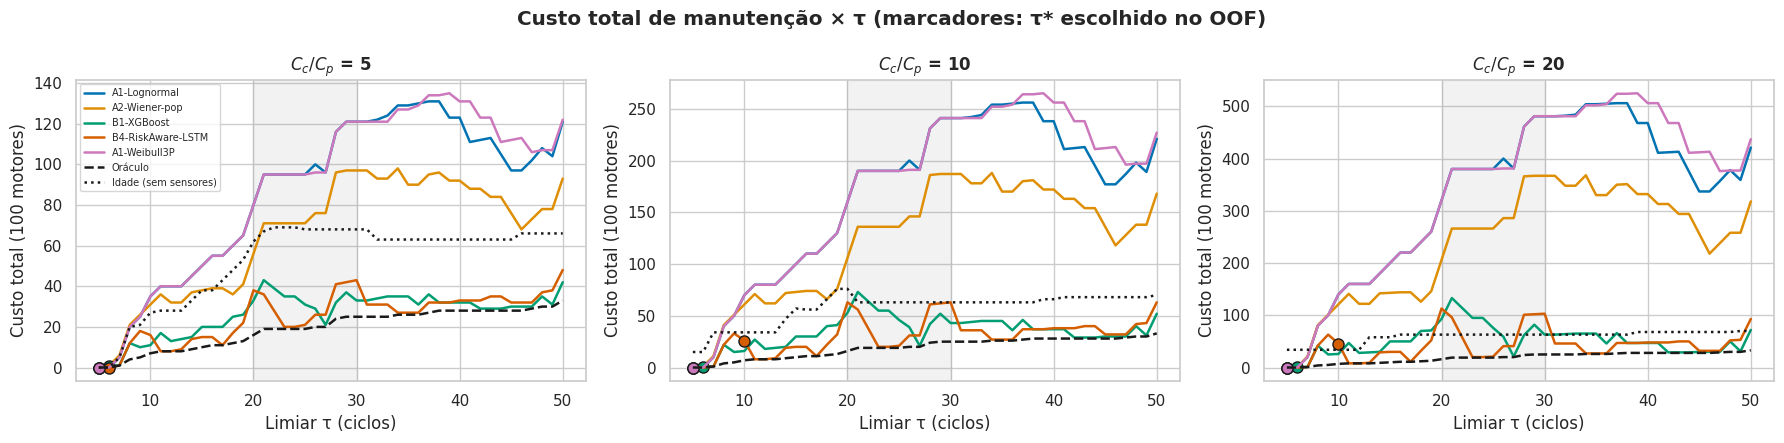

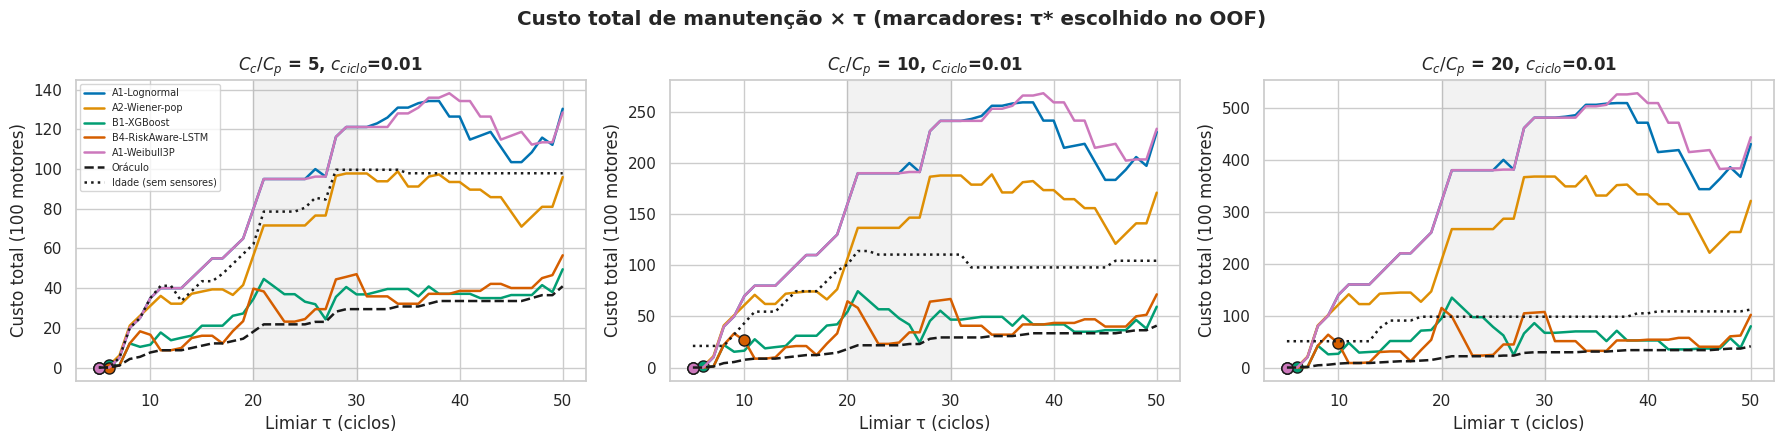

In [ ]:
TAU_STAR = (COSTS[COSTS.split == "oof"].sort_values("custo").groupby(["modelo", "c_ciclo", "razao"], as_index=False).first()
            [["modelo", "c_ciclo", "razao", "tau"]].rename(columns={"tau": "tau_star_oof"}))
plot_models = list(dict.fromkeys(MAIN_MODELS + A_REPS))
for cc in (0.0, C_CYCLE):
    fig, axs = plt.subplots(1, len(COST_RATIOS), figsize=(6 * len(COST_RATIOS), 4.5), sharey=False)
    for ax, ratio in zip(axs, COST_RATIOS):
        sub = COSTS[(COSTS.split == "teste") & (COSTS.c_ciclo == cc) & (COSTS.razao == ratio)]
        for m, col in zip(plot_models, PAL):
            s = sub[sub.modelo == m].sort_values("tau"); ax.plot(s.tau, s.custo, color=col, lw=1.8, label=m)
            ts = int(TAU_STAR[(TAU_STAR.modelo == m) & (TAU_STAR.c_ciclo == cc) & (TAU_STAR.razao == ratio)].tau_star_oof.iloc[0])
            ax.plot(ts, s[s.tau == ts].custo.iloc[0], "o", color=col, ms=8, mec="k")
        for m, sty in (("Oráculo", "k--"), ("Idade (sem sensores)", "k:")):
            s = sub[sub.modelo == m].sort_values("tau"); ax.plot(s.tau, s.custo, sty, lw=1.8, label=m)
        ax.axvspan(20, 30, color="gray", alpha=.1)
        ax.set(title=f"$C_c/C_p$ = {ratio}" + (f", $c_{{ciclo}}$={cc}" if cc else ""), xlabel="Limiar τ (ciclos)", ylabel="Custo total (100 motores)")
    axs[0].legend(fontsize=7)
    fig.suptitle("Custo total de manutenção × τ (marcadores: τ* escolhido no OOF)", fontweight="bold")
    fig.tight_layout(); savefig(fig, f"P1_custo_vs_tau{'_com_custo_ciclo' if cc else ''}")

### 6.3 Tabela final: τ\* (OOF) aplicado no teste, falhas evitadas e economia vs. baseline estatístico

In [ ]:
test_costs = COSTS[COSTS.split == "teste"]
final_rows = []
for _, r in TAU_STAR.iterrows():
    row = test_costs[(test_costs.modelo == r.modelo) & (test_costs.c_ciclo == r.c_ciclo) & (test_costs.razao == r.razao) & (test_costs.tau == r.tau_star_oof)].iloc[0]
    final_rows.append({"modelo": r.modelo, "c_ciclo": r.c_ciclo, "razao": r.razao, "tau_star_oof": int(r.tau_star_oof), "custo_teste": row.custo,
                       "falhas": row.falhas, "prematuras": row.prematuras, "oportunas": row.oportunas})
POLICY = pd.DataFrame(final_rows)
base = POLICY[POLICY.modelo == BEST_A1].set_index(["c_ciclo", "razao"])
POLICY["falhas_evitadas_vs_" + BEST_A1] = POLICY.apply(lambda r: base.loc[(r.c_ciclo, r.razao), "falhas"] - r.falhas, axis=1)
POLICY["economia_%_vs_" + BEST_A1] = POLICY.apply(lambda r: 100 * (base.loc[(r.c_ciclo, r.razao), "custo_teste"] - r.custo_teste) / base.loc[(r.c_ciclo, r.razao), "custo_teste"], axis=1)
POLICY = POLICY.set_index(["c_ciclo", "razao", "modelo"]).sort_index()
display(POLICY); save_table(POLICY, "politica_tau_otimo_custos")
best_pol = POLICY.loc[(0.0, 10)].drop(index="Oráculo").custo_teste.idxmin()
pb = POLICY.loc[(0.0, 10, best_pol)]
md_out(f"Com $C_c/C_p=10$ (sem custo por ciclo), o menor custo de teste entre modelos reais é de **{best_pol}** (τ\\*={pb.tau_star_oof}, custo {pb.custo_teste:.0f}, "
       f"{pb.falhas:.0f} falhas), economia de **{pb[f'economia_%_vs_{BEST_A1}']:.0f}%** sobre o baseline {BEST_A1}. "
       f"Oráculo: custo {POLICY.loc[(0.0, 10, 'Oráculo')].custo_teste:.0f}; preventiva por idade: {POLICY.loc[(0.0, 10, 'Idade (sem sensores)')].custo_teste:.0f}.")

/tmp/ipykernel_947/3013134703.py:10: RuntimeWarning: invalid value encountered in scalar divide
  POLICY["economia_%_vs_" + BEST_A1] = POLICY.apply(lambda r: 100 * (base.loc[(r.c_ciclo, r.razao), "custo_teste"] - r.custo_teste) / base.loc[(r.c_ciclo, r.razao), "custo_teste"], axis=1)
/tmp/ipykernel_947/3013134703.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  POLICY["economia_%_vs_" + BEST_A1] = POLICY.apply(lambda r: 100 * (base.loc[(r.c_ciclo, r.razao), "custo_teste"] - r.custo_teste) / base.loc[(r.c_ciclo, r.razao), "custo_teste"], axis=1)


tau_star_oof  custo_teste  falhas  prematuras  oportunas  falhas_evitadas_vs_A1-Lognormal  economia_%_vs_A1-Lognormal
c_ciclo razao modelo                                                                                                                                     
0.0000  5     A1-Lognormal                     5       0.0000       0           0          0                                0                         NaN
              A1-Weibull2P                     5       0.0000       0           0          0                                0                         NaN
              A1-Weibull3P                     5       0.0000       0           0          0                                0                         NaN
              A2-Wiener-bayes                  5       1.0000       0           1          0                                0                        -inf
              A2-Wiener-pop                    5       0.0000       0           0          0                                0                         NaN
...                                          ...          ...     ...         ...        ...                              ...                         ...
0.0100  20    B2-LSTM                          7      20.0000       1           0          0                               -1                        -inf
              B3-CNN1D                         5       1.0800       0           1          0                                0                        -inf
              B4-RiskAware-LSTM               10      46.5200       2           1          5                               -2                        -inf
              Idade (sem sensores)             7      50.6600       0          33          1                                0                        -inf
              Oráculo                          5       0.0000       0           0          0                                0                         NaN

[66 rows x 7 columns]

Com $C_c/C_p=10$ (sem custo por ciclo), o menor custo de teste entre modelos reais é de **A1-Lognormal** (τ\*=5.0, custo 0, 0 falhas), economia de **nan%** sobre o baseline A1-Lognormal. Oráculo: custo 0; preventiva por idade: 15.

<a id="s7"></a>
# Seção 7 — Exportação final e síntese dinâmica

In [ ]:
def to_jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

SUMMARY = {
    "versoes": VERSIONS, "hardware": HARDWARE, "fonte_contrato_eda": EDA_SOURCE,
    "contrato": {"sensores": SENSORS, "seq_len": SEQ_LEN, "rul_clip": RUL_CLIP, "scaler": "StandardScaler", "folds": N_FOLDS, "seed": SEED,
                 "snapshots_oof": len(VAL_CUTS)},
    "selecao_oof": {"melhor_trilha_B": BEST_B, "melhor_A1": BEST_A1, "melhor_wiener": BEST_WIENER, "HI_escolhido": BEST_HI,
                    "arquitetura_base_B4": BEST_ARCH, "xgb_hiperparametros": XGB_BEST},
    "metricas_teste": MAIN_TABLE.reset_index().to_dict(orient="records"),
    "leaderboard_oof_teste": leaderboard().reset_index().to_dict(orient="records"),
    "wiener": {"parametros": WIENER, "cobertura_IC95": COVERAGE},
    "ablacao_rul_clip": CLIP_ABLATION.reset_index().to_dict(orient="records"),
    "teste_t_ingenuo": NAIVE_T.reset_index().to_dict(orient="records"),
    "shapiro": SHAPIRO.to_dict(orient="records"),
    "wilcoxon_holm": WILCOXON.to_dict(orient="records"),
    "bootstrap_permutacao": BOOT.to_dict(orient="records"),
    "politica_tau_otimo": POLICY.reset_index().to_dict(orient="records"),
}
(OUT_DIR / "modeling_results_summary.json").write_text(json.dumps(SUMMARY, indent=2, ensure_ascii=False, default=to_jsonable), encoding="utf-8")
print("Salvo:", OUT_DIR / "modeling_results_summary.json")

Salvo: /content/drive/MyDrive/Confiabilidade/outputs/modeling/modeling_results_summary.json


In [ ]:
mt = MAIN_TABLE
wil_b = WILCOXON[WILCOXON["signif. 5% (Holm)"] & WILCOXON["B melhor?"]]
pol10 = POLICY.loc[(0.0, 10)]
lines = [
    "## Síntese executiva (gerada na execução)",
    f"- **Hardware:** {HARDWARE.get('gpu') or 'CPU'} · contrato EDA: {EDA_SOURCE}.",
    f"- **Melhor Trilha B (OOF):** {BEST_B} — teste RMSE **{mt.loc[BEST_B, 'RMSE']:.2f}**, MAE {mt.loc[BEST_B, 'MAE']:.2f}, "
    f"NASA total **{mt.loc[BEST_B, 'NASA total']:.1f}**, {mt.loc[BEST_B, '% perigosas']:.0f}% de predições perigosas.",
    f"- **Trilha A:** melhor A1 = {BEST_A1} (RMSE {mt.loc[BEST_A1, 'RMSE']:.2f}); melhor Wiener = {BEST_WIENER} (RMSE {mt.loc[BEST_WIENER, 'RMSE']:.2f}, "
    f"HI-{BEST_HI.upper()}, cobertura IC95 {COVERAGE['bayes' if 'bayes' in BEST_WIENER else 'pop']['cobertura_IC95']:.0%}).",
    f"- **Perda assimétrica ({B4_NAME}):** NASA total {mt.loc[B4_NAME, 'NASA total']:.1f} vs. {mt.loc[BEST_ARCH, 'NASA total']:.1f} da {BEST_ARCH}; "
    f"perigosas {mt.loc[B4_NAME, '% perigosas']:.0f}% vs. {mt.loc[BEST_ARCH, '% perigosas']:.0f}%.",
    f"- **Teto de RUL:** melhor no OOF = {best_clip}; 125 fica a {gap:.2f} ciclos do melhor.",
    f"- **Inferência pareada (N=100):** {len(wil_b)} de {len(WILCOXON)} contrastes Wilcoxon significativos a favor da Trilha B após Holm; "
    f"{len(sig)} de {len(BOOT)} contrastes bootstrap/permutação com IC95 BCa < 0 e p_perm < 0,05. Teste t ingênuo inflado "
    f"{abs(NAIVE_T.t.iloc[0]) / max(abs(NAIVE_T.t.iloc[1]), 1e-9):.1f}× por autocorrelação.",
    f"- **Manutenção ($C_c/C_p$=10):** melhor modelo real {best_pol} com τ*={pol10.loc[best_pol, 'tau_star_oof']}, custo {pol10.loc[best_pol, 'custo_teste']:.0f}, "
    f"{pol10.loc[best_pol, 'falhas']:.0f} falhas; Oráculo {pol10.loc['Oráculo', 'custo_teste']:.0f}; idade {pol10.loc['Idade (sem sensores)', 'custo_teste']:.0f}; "
    f"baseline {BEST_A1} {pol10.loc[BEST_A1, 'custo_teste']:.0f}.",
    f"- **Ressalvas:** só {int((Y_TEST <= 15).sum())} motores de teste com RUL ≤ 15 (custos em τ baixo são ruidosos); "
    f"{M_GT.sum()} motores com RUL > {RUL_CLIP} têm erro estrutural pelo teto; OOF do XGBoost/redes é ligeiramente otimista após o tuning (o teste não).",
]
md_out("\n".join(lines))

## Síntese executiva (gerada na execução)
- **Hardware:** Tesla T4 · contrato EDA: fallback embutido.
- **Melhor Trilha B (OOF):** B1-XGBoost — teste RMSE **14.11**, MAE 10.46, NASA total **334.9**, 58% de predições perigosas.
- **Trilha A:** melhor A1 = A1-Lognormal (RMSE 37.12); melhor Wiener = A2-Wiener-pop (RMSE 25.87, HI-RIDGE, cobertura IC95 64%).
- **Perda assimétrica (B4-RiskAware-LSTM):** NASA total 310.0 vs. 417.3 da B2-LSTM; perigosas 53% vs. 68%.
- **Teto de RUL:** melhor no OOF = 135; 125 fica a 1.80 ciclos do melhor.
- **Inferência pareada (N=100):** 6 de 6 contrastes Wilcoxon significativos a favor da Trilha B após Holm; 9 de 9 contrastes bootstrap/permutação com IC95 BCa < 0 e p_perm < 0,05. Teste t ingênuo inflado 7.6× por autocorrelação.
- **Manutenção ($C_c/C_p$=10):** melhor modelo real A1-Lognormal com τ*=5, custo 0, 0 falhas; Oráculo 0; idade 15; baseline A1-Lognormal 0.
- **Ressalvas:** só 10 motores de teste com RUL ≤ 15 (custos em τ baixo são ruidosos); 11 motores com RUL > 125 têm erro estrutural pelo teto; OOF do XGBoost/redes é ligeiramente otimista após o tuning (o teste não).